# Shuttling benchmark

The three benchmark sweeps below share a single trap geometry, identical RF/MD settings, SION's native voltage-function fitting, and the same **25-interval** optimization grid. All trajectories are centered at each zone: $-d/2 \rightarrow +d/2$.

| Sweep | Analysis points | Actual optimized segmented DC electrodes |
|---|---|---|
| Distance | 10, 20, 30, 40 µm | 10 in each case |
| Electrode count | nominal 7–31 (step 4) | 6, 10, 14, 18, 22, 26, 30 |
| Simultaneous zones | 1, 2, or 3 (moving/held patterns) | **10 per zone**: 10, 20, or 30 total |

### Protocol

- $^{40}\mathrm{Ca}^{+}$, RF peak voltage **20 V** at **20 MHz**; shuttling duration **20 µs**.
- No frequency-preservation penalty (`freq_coeff=0`), but potential minima and positive curvatures are validated. 
- The central DC electrode 0 is not a part of shuttlers. The shuttlers number is increased by adding side DC electrodes from the central electrode for each trap zone.
- SION's analytic voltage fitting is used for every **optimized** electrode.
- Results are checked for ion stability, optimization failure/success. comparison between desired and resulting shuttling trajectories, including MD simulated trajectories. 
- The initial DC state is prepared and cached for the case-specific starting wells.

### Final-run settings

`RUN_SMOKE_ONLY=True` performs the benchmarking procedure. `RUN_SMOKE_ONLY=True` can be used for testing, simulation is only 0.5 us from the full 20 us trajectory.


## 1. Imports and benchmark configuration

In [1]:
from __future__ import annotations
import ast
import hashlib
import importlib.metadata
import json
import os
import platform
import re
import inspect
import subprocess
import sys
import time
import traceback
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import scipy.constants as ct
from scipy.ndimage import uniform_filter1d

import sion as sn
import sion.pylion as pl

# Run 15 physically distinct cases; two exact duplicates are reused in analysis.
RUN_BENCHMARK = False
RUN_SMOKE_ONLY = False   # Final benchmark: full 20-us trajectories; set True for preflight
CASE_IDS_TO_RUN = None  # None = all 15 unique cases; aliases resolve to their source
OPT_REPEATS = 3              # Independent optimization wall-time repetitions
MD_REPEATS = 1               # Matched (1 step, N+1 steps) timing pairs
OUTPUT_MODES = ('with_dump',)  
DUMP_EVERY = 10              
MPI_PROCESSES, OMP_THREADS = 1, 1

T_SHUTTLE_S = 20e-6
OPT_RES = 25                 # Same resolution for shuttling optimization
TANH_N = 4
VMIN, VMAX = -30.0, 30.0
FREQ_COEFF = 0.0  # No secular-frequency-preservation penalty. Can be changed to 0.1, 1...
FREQ_AXES = (1, 2)
USE_ZERO_T_LANGEVIN = False    # Disabled for undamped transport; 
LANGEVIN_DAMPING_S = 5e-6

# Predeclared verification criteria 
MAX_MINIMUM_ERROR_UM = 2.0
# Diagnostic only: frequency drift is recorded, not used as a pass/fail threshold.
MAX_MODE_RELATIVE_DRIFT = 0.20
MAX_WAVEFORM_FIT_ERROR_V = 0.50
MAX_TRAJECTORY_RMSE_UM = 2.0
MAX_ENDPOINT_ERROR_UM = 2.0
FULL_NODE_VERIFICATION = True
DENSE_WAVEFORM_SAMPLES = 201

# Directory
ROOT = Path.cwd() / 'supplementary' / 'shuttling_final_11_controls_per_zone_15_unique'
RAW = ROOT / 'raw'
TRACES = ROOT / 'trajectories'
FIGURES = ROOT / 'figures'
WAVEFORMS = ROOT / 'waveforms'
INITIAL_DC_DIR = ROOT / 'initial_dc'
for directory in (ROOT, RAW, TRACES, FIGURES, WAVEFORMS, INITIAL_DC_DIR):
    directory.mkdir(parents=True, exist_ok=True)

TIMINGS_CSV = RAW / 'timings.csv'
POTENTIAL_CSV = RAW / 'potential_checks.csv'
WAVEFORM_CSV = RAW / 'waveform_checks.csv'
TRAJECTORY_CSV = RAW / 'trajectory_checks.csv'
TRAJECTORY_POINTS_CSV = RAW / 'trajectory_points.csv'
STABILITY_CSV = RAW / 'sion_stability_checks.csv'
INITIAL_DC_CSV = RAW / 'initial_dc_preparation.csv'
ZONE_VOLTAGE_CSV = RAW / 'zone_voltage_diagnostics.csv'
SMOKE_CSV = RAW / 'md_smoke_checks.csv'
ENFORCE_RF_STABILITY = True
MD_SMOKE_TEST = False
MD_SMOKE_DURATION_S = 0.1e-6  
MAX_MD_SMOKE_ERROR_UM = 10.0
SUMMARY_CSV = ROOT / 'case_summary.csv'
BASELINES_CSV = ROOT / 'baseline_summary.csv'

plt.rcParams.update({'font.size': 10, 'axes.grid': True, 'grid.alpha': 0.23,
                     'savefig.bbox': 'tight', 'figure.dpi': 110})
print('Output directory:', ROOT)
print('RF peak voltage: 20 V; optimization intervals (all cases):', OPT_RES)
print('Selected cases:', CASE_IDS_TO_RUN if CASE_IDS_TO_RUN is not None else 'all 15 unique cases')

Output directory: c:\Users\User\Desktop\ARTEM\Sion\benchmark\supplementary\shuttling_final_11_controls_per_zone_15_unique
RF peak voltage: 20 V; optimization intervals (all cases): 25
Selected cases: all 15 unique cases


## 2. Physical trap and reference DC configuration

The researched trap geometry. Each of 3 zones consists of at max 15 electrodes on each side. Initial voltage optimization for trapping ions in each zone is performed here. The optimization intentionally uses all electrodes, and assigns them non-zero value, so they will be considered in MD simulation (for clear benchmark of the shuttling influence on the speed).

Initial loss = 336.10715950544903


Optimizing voltages: 38it [01:20,  2.11s/it]


Final loss = 2.730448166816235e-13
Final uset = [np.float64(0.35466524258784854), np.float64(-0.0161065053712198), np.float64(-0.022602158649349818), np.float64(-0.031760984677216504), np.float64(-0.04647847813607113), np.float64(-0.07148827329355203), np.float64(-0.11266581136191116), np.float64(4.829464285192426), np.float64(-5.206287404478117), np.float64(4.822243335220247), np.float64(-0.11867713822646439), np.float64(-0.07650520604291666), np.float64(-0.05239798307025359), np.float64(-0.038442395487322464), np.float64(-0.03076018946177991), np.float64(-0.027901025223681382), np.float64(-0.02784778767113883), np.float64(-0.03159355933683509), np.float64(-0.039509879133437315), np.float64(-0.05323385558686467), np.float64(-0.0780199796796054), np.float64(-0.12205743555625413), np.float64(4.818859177477175), np.float64(-5.214476430411158), np.float64(4.8186209097490895), np.float64(-0.12206940545912497), np.float64(-0.07804413679332765), np.float64(-0.05282650561905975), np.float64(-

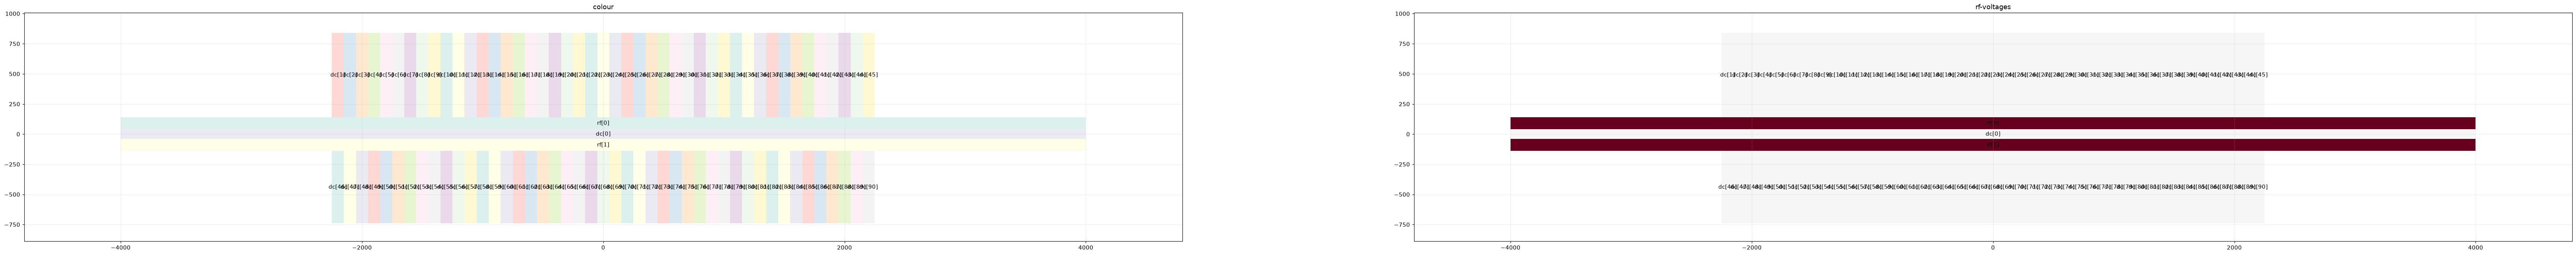

In [2]:
L = 1e-6
Vrf = 20.0                  # RF peak voltage (V)
Omega = 2*np.pi*20e6       # Angular frequency, rad/s
mass = 40*ct.atomic_mass
Z = ct.elementary_charge
Urf = Vrf*np.sqrt(Z/mass)/(2*L*Omega)
scale = Z/((L*Omega)**2*mass)

# Exactly the 90 segmented DC electrodes + one common DC electrode.
top_dc = [[100, 700]]*45
bottom_dc = [[100, 600]]*45
central_dc = [8000, 80]
rftop = [8000, 100]
rfbottom = [8000, 100]

s, RF_coordinates, DC_coordinates = sn.five_wire_trap_design(
    Urf, top_dc, bottom_dc, rftop, rfbottom, central_dc,
    need_coordinates=True, need_plot=True, figsize=[80,20])
N_RF, N_DC = len(RF_coordinates), len(DC_coordinates)
assert (N_RF, N_DC) == (2, 91), (N_RF, N_DC)

rf_null_um = np.asarray(s.minimum((0., 0., 3.), axis=(0, 1, 2),
                                  coord=np.eye(3), method='Newton-CG'), dtype=float)
initial_positions_um = np.array([
    [-1500., 0., rf_null_um[2]],
    [    0., 0., rf_null_um[2]],
    [ 1500., 0., rf_null_um[2]],
])
dc_cell = np.zeros(15)
dc_cell[[6, 7, 8]] = [5., -5., 5.]
start_dc_set = np.concatenate([[0.], np.tile(dc_cell, 6)])
assert len(start_dc_set) == N_DC

dc_set = np.asarray(sn.position_optimization(
    s, initial_positions_um.copy(), start_dc_set.copy(),
    callback_num=1000, voltage_bounds=(-30, 30)), dtype=float).copy()
assert dc_set.shape == (N_DC,)
assert np.isfinite(dc_set).all()

def original_trap_hash():
    h = hashlib.sha256()
    for item in list(RF_coordinates) + list(DC_coordinates):
        a = np.asarray(item, dtype=np.float64)
        h.update(str(a.shape).encode('ascii'))
        h.update(a.tobytes())
    h.update(dc_set.tobytes())
    return h.hexdigest()

GEOMETRY_HASH = original_trap_hash()
TIMESTEP_S = 1.0/(20.0*Omega)   

MD_N_STEPS = int(round(T_SHUTTLE_S/TIMESTEP_S))
print(f'RF minimum (µm) = {rf_null_um}; static DC count={N_DC}; timestep={TIMESTEP_S:.4e} s')
print(f'Time interval = {MD_N_STEPS} steps (~{MD_N_STEPS*TIMESTEP_S*1e6:.6f} µs)')

## 3. Cases, controls, and identical-case reuse

All distance and multi-zone cases use **10 shuttlers per zone**. The shared electrode 0 stays fixed. The six multi-zone patterns include stationary wells with $d=0$. Every moving zone starts at its zone center minus $d/2$. 

Electrode scaling uses **6, 10, 14, 18, 22, 26, 30 shuttlers** for a single central zone.

The complete 17-row case table marks the two exact physical duplicates. Only 15 unique cases are run; summaries and figures reuse `d_010` for `zones_1_10` and `d_040` for `ns_11`.


In [13]:
CENTERS = {'left': (8, 53), 'central': (23, 68), 'right': (38, 83)}
ZONE_ORDER = ('left', 'central', 'right')

def make_shuttler_configuration(n_s, n_z):
    if n_s < 7 or (n_s - 3) % 4 != 0:
        raise ValueError('Valid n_s: 7, 11, 15, ..., 31.')
    if n_z not in (1, 2, 3):
        raise ValueError('n_z must be 1, 2 or 3')
    offset = (n_s - 3) // 4
    selected_zones = {1: ('central',), 2: ('left', 'central'),
                      3: ('left', 'central', 'right')}[n_z]
    zone_controls = {}
    for zone in selected_zones:
        c1, c2 = CENTERS[zone]
        ids = list(range(c1-offset, c1+offset+1))
        ids += list(range(c2-offset, c2+offset+1))
        zone_controls[zone] = np.asarray(ids, dtype=int)
        assert len(zone_controls[zone]) == n_s - 1
    ids = np.unique(np.concatenate(list(zone_controls.values())))
    if np.any(ids == 0) or ids[0] < 1 or ids[-1] >= N_DC:
        raise ValueError('Unexpected or shared control index')
    if len(ids) != n_z*(n_s-1):
        raise ValueError('Segmented control sets unexpectedly overlap')
    centers = initial_positions_um[[ZONE_ORDER.index(z) for z in selected_zones]].copy()
    return ids, centers, selected_zones, zone_controls

CONFIGURATIONS = {
    'd_scale': {'d': [10, 20, 30, 40]},
    'n_s_scale': {'n_s': [7, 11, 15, 19, 23, 27, 31]},
    'n_z_scale': {'n_z_pairs': [(1, [10]), (2, [10, 0]), (2, [10, 10]),
                              (3, [0, 10, 0]), (3, [10, 10, 0]),
                              (3, [10, 10, 10])]},
}

def get_cases():
    cases = []
    for d in CONFIGURATIONS['d_scale']['d']:
        cases.append({'case_id': f'd_{d:03d}', 'family': 'd_scale',
                      'n_s_nominal': 11, 'n_z': 1, 'distances_um': [float(d)]})
    for n_s in CONFIGURATIONS['n_s_scale']['n_s']:
        cases.append({'case_id': f'ns_{n_s:02d}', 'family': 'n_s_scale',
                      'n_s_nominal': n_s, 'n_z': 1, 'distances_um': [40.]})
    for n_z, ds in CONFIGURATIONS['n_z_scale']['n_z_pairs']:
        cases.append({'case_id': f'zones_{n_z}_' + '-'.join(map(str, ds)),
                      'family': 'n_z_scale', 'n_s_nominal': 11,
                      'n_z': n_z, 'distances_um': list(map(float, ds))})
    for case in cases:
        ids, centers, zones, zone_controls = make_shuttler_configuration(
            case['n_s_nominal'], case['n_z'])
        distances = np.asarray(case['distances_um'], dtype=float)
        starts = centers.copy()
        starts[:, 0] -= distances/2
        all_starts = initial_positions_um.copy()
        for i, zone in enumerate(zones):
            all_starts[ZONE_ORDER.index(zone)] = starts[i]
        case['shuttlers'] = ids
        case['centers_um'] = centers
        case['starts_um'] = starts
        case['all_start_positions_um'] = all_starts
        case['zone_names'] = zones
        case['zone_local_electrodes'] = zone_controls
        case['n_variables'] = len(ids)
        case['opt_res'] = OPT_RES
        case['n_opt_nodes'] = OPT_RES + 1
        case['n_moving'] = int(np.count_nonzero(distances))
        assert len(starts) == case['n_z'] == len(distances)
        assert len(ids) == (case['n_s_nominal']-1)*case['n_z']
        assert all(np.isin(rows, ids).all() for rows in zone_controls.values())
    return cases

CASES = get_cases()
# Exact duplicates are visible in tables/figures but NEVER measured twice.
REUSE_CASE = {'zones_1_10': 'd_010', 'ns_11': 'd_040'}
CASE_BY_ID = {c['case_id']: c for c in CASES}

for alias, source in REUSE_CASE.items():
    a, b = CASE_BY_ID[alias], CASE_BY_ID[source]
    for key in ('n_z', 'n_s_nominal', 'n_variables', 'opt_res', 'n_opt_nodes'):
        assert a[key] == b[key], f'{alias} differs from {source}: {key}'
    for key in ('shuttlers', 'starts_um', 'centers_um', 'all_start_positions_um'):
        assert np.array_equal(a[key], b[key]), f'{alias} differs from {source}: {key}'
    assert a['distances_um'] == b['distances_um']
    assert a['zone_names'] == b['zone_names']
    for zone in a['zone_names']:
        assert np.array_equal(a['zone_local_electrodes'][zone],
                              b['zone_local_electrodes'][zone])
    assert a['n_z'] == b['n_z'] == 1

for case in CASES:
    case['source_case_id'] = REUSE_CASE.get(case['case_id'], case['case_id'])
    case['reused_measurement'] = (case['source_case_id'] != case['case_id'])
RUN_CASES = [c for c in CASES if not c['reused_measurement']]
assert len(RUN_CASES) == 15
assert len(CASES) == 17
assert [c['distances_um'][0] for c in CASES if c['family'] == 'd_scale'] == [10., 20., 30., 40.]
assert all(c['opt_res'] == 25 for c in CASES)
assert all(c['n_variables'] == 10 for c in CASES if c['family'] == 'd_scale')
assert [make_shuttler_configuration(11, n)[0].size for n in (1, 2, 3)] == [10, 20, 30]
assert [make_shuttler_configuration(n, 1)[0].size for n in CONFIGURATIONS['n_s_scale']['n_s']] == [n-1 for n in CONFIGURATIONS['n_s_scale']['n_s']]
assert all(0 not in c['shuttlers'] for c in CASES)
assert all(c['n_variables'] == c['n_z']*(c['n_s_nominal']-1) for c in CASES)
assert [c['n_variables'] for c in CASES if c['family']=='n_z_scale'] == [10, 20, 20, 30, 30, 30]
for case in CASES:
    end = case['starts_um'][:, 0] + np.asarray(case['distances_um'])
    expected_end = case['centers_um'][:, 0] + np.asarray(case['distances_um'])/2
    assert np.allclose(end, expected_end)
case_table = pd.DataFrame([{
    'case_id': c['case_id'], 'family': c['family'], 'n_z': c['n_z'],
    'n_moving': c['n_moving'], 'distances_um': str(c['distances_um']),
    'source_case_id': c['source_case_id'], 'reused_measurement': c['reused_measurement'],
    'n_s_nominal_including_0': c['n_s_nominal'],
    'n_optimized_DC_per_zone': c['n_s_nominal'] - 1,
    'n_optimized_DC_variables': c['n_variables'],
    'start_x_um': str(c['starts_um'][:, 0].tolist()),
    'end_x_um': str((c['starts_um'][:, 0] + c['distances_um']).tolist()),
    'optimization_intervals': c['opt_res'], 'optimization_nodes': c['n_opt_nodes'],
} for c in CASES])
display(case_table)


,case_id,family,n_z,n_moving,distances_um,source_case_id,reused_measurement,n_s_nominal_including_0,n_optimized_DC_per_zone,n_optimized_DC_variables,start_x_um,end_x_um,optimization_intervals,optimization_nodes
0,d_010,d_scale,1,1,[10.0],d_010,False,11,10,10,[-5.0],[5.0],25,26
1,d_020,d_scale,1,1,[20.0],d_020,False,11,10,10,[-10.0],[10.0],25,26
2,d_030,d_scale,1,1,[30.0],d_030,False,11,10,10,[-15.0],[15.0],25,26
3,d_040,d_scale,1,1,[40.0],d_040,False,11,10,10,[-20.0],[20.0],25,26
4,ns_07,n_s_scale,1,1,[40.0],ns_07,False,7,6,6,[-20.0],[20.0],25,26
5,ns_11,n_s_scale,1,1,[40.0],d_040,True,11,10,10,[-20.0],[20.0],25,26
6,ns_15,n_s_scale,1,1,[40.0],ns_15,False,15,14,14,[-20.0],[20.0],25,26
7,ns_19,n_s_scale,1,1,[40.0],ns_19,False,19,18,18,[-20.0],[20.0],25,26
8,ns_23,n_s_scale,1,1,[40.0],ns_23,False,23,22,22,[-20.0],[20.0],25,26
9,ns_27,n_s_scale,1,1,[40.0],ns_27,False,27,26,26,[-20.0],[20.0],25,26


## 3b. Stability test

Checks stability from the stability() function to verify that the trap hold ions.
The pass/fail value is taken directly from SION's **`is_stable`** key. 


In [4]:
PHYSICAL_RF_RFS = np.asarray(s.rfs, dtype=float).copy() * (Vrf / Urf)


def local_rf_stability(position_um, dc_voltages):
    dcs = np.r_[np.zeros(N_RF), np.asarray(dc_voltages, dtype=float)]
    with s.with_voltages(dcs=dcs, rfs=PHYSICAL_RF_RFS):
        result = sn.stability(s, mass, Omega, np.asarray(position_um),
                              charges=1, L=L, need_plot=False)
    ion = result['Ion (M = 40, Z = 1)']
    flag = ion['is_correct'] if 'is_correct' in ion else ion['is_stable']
    if not isinstance(flag, (bool, np.bool_)):
        raise TypeError('SION stability flag must be a boolean')
    return {'stable': bool(flag), 'is_correct': bool(flag),
            'a': ion['a'], 'q': ion['q']}


def initial_rf_preflight():
    print('SION stability() preflight (no plots), static starting wells:')
    results = []
    for i, well in enumerate(initial_positions_um):
        verdict = local_rf_stability(well, dc_set)
        results.append(verdict)
        print(f'  well {i}: a={verdict["a"]:.4g}, q={verdict["q"]:.4g}, '
              f'is_correct={verdict["is_correct"]}')
    if ENFORCE_RF_STABILITY and not all(r['is_correct'] for r in results):
        raise RuntimeError('SION stability() rejected the starting RF/DC configuration.')
    return results


## 4. Route and waveform fitting tests

The shuttling optimizer returns discrete voltages and analytic LAMMPS expressions. SION uses a tanh or Gaussian fit to each voltage row. The fit must be checked in volts at nodes before evaluating dynamics. Expressions are parsed with a restricted AST evaluator; only mathematical operations and recognized functions are allowed.

In [5]:
def route_fraction(t_s, T=T_SHUTTLE_S, N=TANH_N):
    t = np.asarray(t_s, dtype=float)
    return 0.5*(np.tanh(N*(2*t/T - 1))/np.tanh(N) + 1.)

def desired_trajectory_um(case, t_s):
    t = np.atleast_1d(np.asarray(t_s, dtype=float))
    fractions = route_fraction(t)
    out = np.broadcast_to(case['starts_um'][None, :, :],
                          (len(t), case['n_z'], 3)).copy()
    out[:, :, 0] += fractions[:, None] * np.asarray(case['distances_um'])[None, :]
    return out

_ALLOWED_FUNCS = {'exp': np.exp, 'sin': np.sin, 'cos': np.cos,
                  'sqrt': np.sqrt, 'tanh': np.tanh, 'abs': np.abs}
_ALLOWED_AST = (ast.Expression, ast.Call, ast.Load, ast.BinOp, ast.UnaryOp,
                ast.Name, ast.Constant, ast.Add, ast.Sub, ast.Mult,
                ast.Div, ast.Pow, ast.UAdd, ast.USub)

def evaluate_lammps_function(expr, time_s):
    text = re.sub(r'\bstep\s*\*\s*dt\b', 't', str(expr)).replace('^', '**')
    tree = ast.parse(text, mode='eval')
    for node in ast.walk(tree):
        if not isinstance(node, _ALLOWED_AST):
            raise ValueError(f'Unsupported expression syntax: {type(node).__name__}: {expr}')
        if isinstance(node, ast.Name) and node.id not in (set(_ALLOWED_FUNCS) | {'t', 'pi'}):
            raise ValueError(f'Unrecognized identifier {node.id}: {expr}')
        if isinstance(node, ast.Call) and not (
            isinstance(node.func, ast.Name) and node.func.id in _ALLOWED_FUNCS
            and not node.keywords):
            raise ValueError(f'Unsupported function call: {expr}')
    t = np.atleast_1d(np.asarray(time_s, dtype=float))
    with np.errstate(over='ignore', under='ignore', invalid='ignore'):
        out = eval(compile(tree, '<SION analytic waveform>', 'eval'),
                   {'__builtins__': {}}, {**_ALLOWED_FUNCS, 't': t, 'pi': np.pi})
    arr = np.asarray(out, dtype=float)
    return np.broadcast_to(arr, t.shape).copy()

def evaluate_waveform_functions(funcs, time_s):
    return np.vstack([evaluate_lammps_function(f, time_s) for f in funcs])

## 5. File, provenance and timing helpers

Every raw timing measurement is saved with its case, repetition, mode, step count, and error status. Record files are updated immediately after each experiment so that completed measurements can be reused after an interrupted kernel session. A configuration fingerprint prevents accidental mixing of incompatible benchmark settings.

If you analyse already completed data - ignore the raised error and move on to the next cells.

In [6]:
def save_csv_atomic(df, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + '.tmp')
    df.to_csv(tmp, index=False)
    os.replace(tmp, path)

def read_table(path):
    return pd.read_csv(path) if Path(path).is_file() else pd.DataFrame()

def upsert_rows(path, new_rows, keys):
    if not new_rows:
        return
    previous = read_table(path)
    added = pd.DataFrame(new_rows)
    combined = pd.concat([previous, added], ignore_index=True)
    combined = combined.drop_duplicates(subset=keys, keep='last')
    save_csv_atomic(combined, path)

def package_version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return None

def sion_source_metadata():
    try:
        p = Path(inspect.getfile(sn)).resolve()
        main = p.parent / 'sion.py' if p.name == '__init__.py' else p
        target = main if main.is_file() else p
        return {'path': str(target), 'sha256': hashlib.sha256(target.read_bytes()).hexdigest()}
    except Exception:
        return {'path': None, 'sha256': None}

def git_revision():
    try:
        return subprocess.check_output(['git', 'rev-parse', 'HEAD'], text=True,
                                       cwd=Path.cwd(), stderr=subprocess.DEVNULL,
                                       timeout=3).strip()
    except Exception:
        return None

BENCH_PARAMS = dict(
    T_shuttle_s=T_SHUTTLE_S, default_opt_res=OPT_RES,
    opt_res_by_case={c['case_id']: c['opt_res'] for c in CASES}, tanh_n=TANH_N,
    vmin=VMIN, vmax=VMAX, freq_coeff=FREQ_COEFF, freq_axes=FREQ_AXES,
    trajectory='zone_center_minus_half_distance_to_plus_half_distance',
    optimize_common_dc_electrode_0=False,
    nominal_controls_include_common_electrode_0=True,
    optimized_variables_by_case={c['case_id']: c['n_variables'] for c in CASES},
    case_measurement_sources={c['case_id']: c['source_case_id'] for c in CASES},
    unique_case_count=len(RUN_CASES), analysis_point_count=len(CASES),
    static_reference_per_case=True,
    rf_frequency_hz=Omega/(2*np.pi), rf_voltage_peak=Vrf,
    geometry_hash=GEOMETRY_HASH, timestep_s=TIMESTEP_S, md_n_steps=MD_N_STEPS,
    output_modes=OUTPUT_MODES, dump_every=DUMP_EVERY,
    enforce_rf_stability=ENFORCE_RF_STABILITY,
    stability_method='sion.stability', stability_requires_is_correct=True,
    stability_need_plot=False,
    md_smoke_duration_s=MD_SMOKE_DURATION_S,
    max_md_smoke_error_um=MAX_MD_SMOKE_ERROR_UM,
    max_potential_error_um=MAX_MINIMUM_ERROR_UM,
    max_mode_drift=MAX_MODE_RELATIVE_DRIFT, max_waveform_fit_error_v=MAX_WAVEFORM_FIT_ERROR_V,
    mpi_processes=MPI_PROCESSES, omp_threads=OMP_THREADS,
    use_zero_t_langevin=USE_ZERO_T_LANGEVIN, langevin_damping_s=LANGEVIN_DAMPING_S,
)
BENCH_ID = hashlib.sha256(json.dumps(BENCH_PARAMS, sort_keys=True).encode()).hexdigest()[:16]
CONFIG_JSON = ROOT / 'configuration.json'
provenance = dict(benchmark_id=BENCH_ID, parameters=BENCH_PARAMS,
                  python=sys.version, platform=platform.platform(),
                  processor=platform.processor(), cpu_count=os.cpu_count(),
                  versions={
                      'surface-ion': package_version('surface-ion'),
                      'numpy': np.__version__, 'scipy': scipy.__version__,
                      'pandas': pd.__version__,
                      'matplotlib': package_version('matplotlib'),
                  }, working_directory_git_revision=git_revision(),
                  sion_source=sion_source_metadata(),
                  runtime_settings={'run_benchmark': RUN_BENCHMARK, 'smoke_only': RUN_SMOKE_ONLY,
                                    'md_smoke_test': MD_SMOKE_TEST,
                                    'opt_repeats': OPT_REPEATS, 'md_repeats': MD_REPEATS,
                                    'case_ids': CASE_IDS_TO_RUN})
if CONFIG_JSON.exists():
    old = json.loads(CONFIG_JSON.read_text(encoding='utf-8'))
    if old.get('benchmark_id') != BENCH_ID:
        raise RuntimeError('Existing data use a different benchmark configuration. '
                           'Change ROOT or move the old output folder before continuing.')
else:
    CONFIG_JSON.write_text(json.dumps(provenance, indent=2, default=str), encoding='utf-8')
print('Benchmark ID:', BENCH_ID)
print('Runtime settings are intentionally not part of the waveform cache key.')
with (ROOT / 'run_settings.jsonl').open('a', encoding='utf-8') as fh:
    fh.write(json.dumps({'utc': pd.Timestamp.now(tz='UTC').isoformat(),
                         'runtime_settings': provenance['runtime_settings']}) + '\n')

def already_done(path, selectors):
    df = read_table(path)
    if df.empty:
        return False
    matched = np.ones(len(df), dtype=bool)
    for key, value in selectors.items():
        if key not in df.columns:
            return False
        matched &= (df[key].astype(str).to_numpy() == str(value))
    return bool(np.any(matched))

def safe_execute(sim):
    start = time.perf_counter()
    sim.execute(mpi_processes=MPI_PROCESSES, omp_threads=OMP_THREADS)
    return time.perf_counter() - start

RuntimeError: Existing data use a different benchmark configuration. Change ROOT or move the old output folder before continuing.

## 6. Static initialization, shuttling optimization, waveform storage and checks

For each case, prepare the static DC solution with SION `position_optimization`. Cache it in `initial_dc/` and validate the actual starting wells before using it. Its runtime is recorded separately in `raw/initial_dc_preparation.csv`.

All subsequent SION shuttling optimization calls use `freq_coeff=0`, only the selected shuttlers, and `res=25`. The initial DC set and waveforms are cached together so invalid cross-case reuse is rejected.


SION approximations on inactive DC electrodes are replaced by exact constants
from the independently prepared initial DC vector, after verifying that their
raw optimization nodes never change. Active-electrode fit errors remain subject
to the original 0.5 V verification threshold.


In [7]:
def initial_dc_cache_path(case):
    h = hashlib.sha256()
    h.update(GEOMETRY_HASH.encode())
    h.update(np.asarray(case['all_start_positions_um'], dtype=np.float64).tobytes())
    return INITIAL_DC_DIR / (h.hexdigest()[:20] + '.npz')

def case_initial_dc(case):
    if 'initial_dc_set' in case:
        return case['initial_dc_set']
    path = initial_dc_cache_path(case)
    if path.exists():
        with np.load(path) as saved:
            assert np.array_equal(saved['positions_um'], case['all_start_positions_um'])
            initial = np.asarray(saved['voltages'], dtype=float)
    else:
        t0 = time.perf_counter()
        initial = np.asarray(sn.position_optimization(
            s, case['all_start_positions_um'].copy(), dc_set.copy(),
            callback_num=1000, voltage_bounds=(-30, 30)), dtype=float).copy()
        if initial.shape != (N_DC,) or not np.all(np.isfinite(initial)):
            raise RuntimeError('Invalid case-specific static initial DC voltages')
        np.savez_compressed(path, positions_um=case['all_start_positions_um'],
                            voltages=initial)
        upsert_rows(INITIAL_DC_CSV, [dict(
            cache_name=path.name, seconds=time.perf_counter()-t0,
            description='untimed initial position_optimization')], ['cache_name'])
    if initial.shape != (N_DC,) or not np.all(np.isfinite(initial)):
        raise RuntimeError('Invalid cached initial DC configuration')
    case['initial_dc_set'] = initial
    return initial

def check_initial_wells(case):
    initial = case_initial_dc(case)
    errs = []
    for target in case['starts_um']:
        found, curvature = minima_and_curvatures(initial, target)
        err = float(np.linalg.norm(found-target))
        errs.append(err)
        if not np.all(np.isfinite(curvature)) or not np.all(curvature > 0):
            raise RuntimeError('Static preconditioning did not produce a confined minimum')
    if max(errs) > 1.0:
        raise RuntimeError(f'Initial static wells differ from requested centered starts: {errs} µm')
    print('  Prepared static start at x (µm):', case['starts_um'][:, 0],
          '; maximum well mismatch =', f'{max(errs):.4g} µm')
    return initial

def optimize_case(case):
    shuttlers = case['shuttlers'].tolist()
    starts = case['starts_um'].copy()
    dc_work = case_initial_dc(case).copy()
    if case['n_z'] == 1:
        return sn.linear_shuttling_voltage(
            s, starts[0], float(case['distances_um'][0]), T_SHUTTLE_S, dc_work,
            shuttlers=shuttlers, N=TANH_N, vmin=VMIN, vmax=VMAX,
            res=case['opt_res'], L=L, need_func=True, freq_coeff=FREQ_COEFF,
            freq_ax=list(FREQ_AXES))

    def routes(i, t):
        return np.array([float(case['distances_um'][i])*route_fraction(t), 0., 0.])
    return sn.shuttling_voltage(
        s, starts, routes, T_SHUTTLE_S, dc_work,
        shuttlers=shuttlers, vmin=VMIN, vmax=VMAX, res=case['opt_res'],
        L=L, need_func=True, freq_coeff=FREQ_COEFF,
        freq_ax=FREQ_AXES)

def fix_inactive_voltage_functions(case, voltages, funcs):
    voltages = np.asarray(voltages, dtype=float)
    funcs = list(funcs)
    if voltages.shape != (N_DC, case['n_opt_nodes']) or len(funcs) != N_DC:
        raise ValueError('Unexpected number of DC voltage nodes or functions')
    inactive = np.setdiff1d(np.arange(N_DC), case['shuttlers'])
    initial = case_initial_dc(case)
    max_change = float(np.max(np.abs(voltages[inactive] - initial[inactive, None])))
    if max_change > 1e-6:
        raise ValueError(f'Inactive DC channels changed by {max_change:.3g} V')
    for i in inactive:
        funcs[i] = f'({float(initial[i]):.17g})'
    return funcs


def artifact_paths(case):
    return (WAVEFORMS / (case['case_id'] + '_voltages.npz'),
            WAVEFORMS / (case['case_id'] + '_functions.json'))

def save_waveform(case, voltages, funcs):
    vpath, fpath = artifact_paths(case)
    np.savez_compressed(vpath, voltages=np.asarray(voltages, dtype=float),
                        electrode_indices=np.asarray(case['shuttlers']),
                        nodes_s=np.linspace(0, T_SHUTTLE_S, case['n_opt_nodes']),
                        optimization_intervals=np.array(case['opt_res']),
                        initial_dc_set=case_initial_dc(case))
    fpath.write_text(json.dumps([str(f) for f in funcs], indent=2), encoding='utf-8')

def load_waveform(case):
    vpath, fpath = artifact_paths(case)
    if not vpath.exists() or not fpath.exists():
        return None
    with np.load(vpath) as archive:
        vs = np.asarray(archive['voltages'], dtype=float)
        stored_ids = archive['electrode_indices']
        if not np.array_equal(stored_ids, case['shuttlers']):
            raise RuntimeError('Waveform electrode-index mismatch for ' + case['case_id'])
        if archive['voltages'].shape != (N_DC, case['n_opt_nodes']):
            raise RuntimeError('Wrong saved node count for ' + case['case_id'])
        if not np.array_equal(archive['nodes_s'],
                              np.linspace(0, T_SHUTTLE_S, case['n_opt_nodes'])):
            raise RuntimeError('Saved waveform time grid mismatch')
        if not np.allclose(archive['initial_dc_set'], case_initial_dc(case), atol=1e-12, rtol=0):
            raise RuntimeError('Waveform initial voltages have changed')
    funcs = json.loads(fpath.read_text(encoding='utf-8'))
    funcs = fix_inactive_voltage_functions(case, vs, funcs)
    if vs.shape != (N_DC, case['n_opt_nodes']) or len(funcs) != N_DC:
        raise RuntimeError('Wrong waveform shape for ' + case['case_id'])
    return vs, funcs

def run_optimization_repetitions(case):
    cached = load_waveform(case)
    for rep in range(OPT_REPEATS):
        selector = {'case_id': case['case_id'], 'kind': 'optimization',
                    'repeat': rep, 'mode': 'solver', 'steps': 0}
        if already_done(TIMINGS_CSV, selector) and cached is not None:
            continue
        try:
            t0 = time.perf_counter()
            voltages, funcs = optimize_case(case)
            elapsed = time.perf_counter() - t0
            voltages = np.asarray(voltages, dtype=float)
            if voltages.shape != (N_DC, case['n_opt_nodes']) or len(funcs) != N_DC:
                raise ValueError(f'Unexpected optimization output: {voltages.shape}, {len(funcs)} funcs')
            if not np.isfinite(voltages).all():
                raise ValueError('Non-finite optimization voltages')
            funcs = fix_inactive_voltage_functions(case, voltages, funcs)
            if cached is None:
                save_waveform(case, voltages, funcs)
                cached = (voltages, funcs)
            row = dict(case_id=case['case_id'], kind='optimization', mode='solver',
                       repeat=rep, steps=0, seconds=elapsed, assembly_s=np.nan,
                       status='ok', error='', n_z=case['n_z'],
                       n_variables=case['n_variables'], opt_res=case['opt_res'])
        except Exception as exc:
            row = dict(case_id=case['case_id'], kind='optimization', mode='solver',
                       repeat=rep, steps=0, seconds=np.nan, assembly_s=np.nan,
                       status='failed', error=f'{type(exc).__name__}: {exc}',
                       n_z=case['n_z'], n_variables=case['n_variables'])
            print('Optimization failed:', case['case_id'], rep, row['error'])
        upsert_rows(TIMINGS_CSV, [row], ['case_id', 'kind', 'mode', 'repeat', 'steps'])
    return cached

def waveform_validation(case, voltages, funcs):
    nodes_t = np.linspace(0, T_SHUTTLE_S, case['n_opt_nodes'])
    dense_t = np.linspace(0, T_SHUTTLE_S, DENSE_WAVEFORM_SAMPLES)
    fit_nodes = evaluate_waveform_functions(funcs, nodes_t)
    fit_dense = evaluate_waveform_functions(funcs, dense_t)
    interpolated_dense = np.vstack([np.interp(dense_t, nodes_t, vs)
                                    for vs in voltages])
    diff_nodes = fit_nodes-voltages
    diff_dense = fit_dense-interpolated_dense
    selected = case['shuttlers']
    static = np.setdiff1d(np.arange(N_DC), selected)
    rows = []
    for typ, diff in [('node', diff_nodes), ('dense_interpolated', diff_dense)]:
        for e in range(N_DC):
            rows.append(dict(case_id=case['case_id'], electrode=e, check=typ,
                             rmse_v=float(np.sqrt(np.mean(diff[e]**2))),
                             max_error_v=float(np.max(np.abs(diff[e]))),
                             dynamic=bool(np.ptp(voltages[e]) > 1e-4),
                             optimized_variable=bool(e in selected)))
    max_fit = float(np.max(np.abs(diff_nodes)))
    max_dense = float(np.max(np.abs(diff_dense)))
    range_violation = float(max(
        np.max(VMIN - voltages[selected]), np.max(voltages[selected] - VMAX),
        np.max(VMIN - fit_dense[selected]), np.max(fit_dense[selected] - VMAX), 0.0))
    inactive_change = float(np.max(np.abs(voltages[static] - case_initial_dc(case)[static, None])))
    return rows, dict(case_id=case['case_id'],
                      waveform_node_max_v=max_fit, waveform_dense_max_v=max_dense,
                      waveform_range_violation_v=range_violation,
                      inactive_voltage_change_v=inactive_change,
                      n_active_voltage_rows=int(np.sum(np.ptp(voltages, axis=1) > 1e-4)),
                      n_analytic_dynamic_funcs=int(sum('step' in str(f) for f in funcs)),
                      mean_func_length=float(np.mean([len(str(f)) for f in funcs])),
                      waveform_pass=(max_fit <= MAX_WAVEFORM_FIT_ERROR_V and
                                     max_dense <= MAX_WAVEFORM_FIT_ERROR_V and
                                     range_violation < 1e-6 and inactive_change < 1e-6))

def zone_voltage_diagnostics(case, voltages):
    result = []
    peak_to_peak = np.ptp(np.asarray(voltages, dtype=float), axis=1)
    for i, zone in enumerate(case['zone_names']):
        local_ids = case['zone_local_electrodes'][zone]
        moving = abs(case['distances_um'][i]) > 0.0
        result.append(dict(case_id=case['case_id'], zone=zone, zone_index=i,
            role='moving' if moving else 'stationary',
            commanded_displacement_um=float(case['distances_um'][i]),
            n_local_controls=len(local_ids),
            n_varying_local_controls=int(np.sum(peak_to_peak[local_ids] > 1e-4)),
            local_max_voltage_change_v=float(np.max(peak_to_peak[local_ids])),
            shared_electrode_change_v=float(peak_to_peak[0])))
    return result


## 7. Independent potential-minimum and confinement checks

For each discrete node and sampled fitted-waveform time, recompute the actual pseudopotential minimum and mode curvatures. RF stability is checked separately with SION `stability()`. Frequency drift relative to the per-case starting well is recorded. Minimum-position mismatch remains a rejection criterion.

In [8]:
def minima_and_curvatures(dc_voltages, requested_um):
    with s.with_voltages(dcs=np.concatenate([np.zeros(N_RF), dc_voltages]), rfs=None):
        actual = np.asarray(s.minimum(
            np.asarray(requested_um, dtype=float)*1.0001,
            axis=(0, 1, 2), coord=np.eye(3), method='Newton-CG'), dtype=float)
        curvature, _ = s.modes(actual, sorted=False)
    curvature = np.asarray(curvature, dtype=float)
    if actual.shape != (3,) or curvature.shape != (3,):
        raise ValueError(f'Unexpected minimum/curvature shapes: {actual.shape}, {curvature.shape}')
    return actual, curvature

def reference_curvatures(case):
    ref = []
    for start in case['starts_um']:
        actual, curv = minima_and_curvatures(case_initial_dc(case).copy(), start)
        if not (np.all(np.isfinite(curv)) and np.all(curv > 0)):
            raise RuntimeError('Unstable initial trap minimum: ' + str(curv))
        ref.append(curv)
    return np.array(ref)

def potential_checks(case, voltages, funcs):
    base_curv = reference_curvatures(case)
    nodes_t = np.linspace(0, T_SHUTTLE_S, case['n_opt_nodes'])
    indices = np.arange(case['n_opt_nodes']) if FULL_NODE_VERIFICATION else np.unique(
        np.linspace(0, case['opt_res'], 7).astype(int))
    fitted_t = np.unique(np.r_[
        nodes_t[np.unique(np.linspace(0, case['opt_res'], 7).astype(int))],
        0.5*(nodes_t[:-1]+nodes_t[1:])[np.unique(
            np.linspace(0, case['opt_res']-1, 6).astype(int))]])
    tasks = [('optimized', float(nodes_t[i]), voltages[:, i]) for i in indices]
    fitted = evaluate_waveform_functions(funcs, fitted_t)
    tasks += [('fitted', float(t), fitted[:, k]) for k, t in enumerate(fitted_t)]
    records = []
    for phase, t, v in tasks:
        targets = desired_trajectory_um(case, [t])[0]
        for i, target in enumerate(targets):
            row = dict(case_id=case['case_id'], phase=phase,
                       zone=case['zone_names'][i], zone_index=i,
                       role='moving' if abs(case['distances_um'][i]) > 0 else 'stationary',
                       commanded_displacement_um=float(case['distances_um'][i]),
                       time_us=t*1e6,
                       target_x_um=target[0], target_y_um=target[1], target_z_um=target[2])
            try:
                position, curv = minima_and_curvatures(v, target)
                err = position - target
                if not np.all(np.isfinite(curv)) or not np.all(curv > 0):
                    raise ValueError('Non-positive/non-finite curvature: ' + str(curv))
                ratio = np.sqrt(curv[list(FREQ_AXES)]/base_curv[i, list(FREQ_AXES)]) - 1
                row.update(actual_x_um=position[0], actual_y_um=position[1],
                           actual_z_um=position[2], error_3d_um=np.linalg.norm(err),
                           error_axial_um=err[0], relative_mode_drift=float(np.max(np.abs(ratio))),
                           stable=True, status='ok', error='')
            except Exception as exc:
                row.update(actual_x_um=np.nan, actual_y_um=np.nan, actual_z_um=np.nan,
                           error_3d_um=np.nan, error_axial_um=np.nan,
                           relative_mode_drift=np.nan, stable=False,
                           status='failed', error=f'{type(exc).__name__}: {exc}')
            records.append(row)
    return records

def summarize_potential_checks(rows):
    df = pd.DataFrame(rows)
    out = {}
    for phase in ('optimized', 'fitted'):
        block = df[df['phase'] == phase]
        prefix = phase + '_'
        valid = block['status'].eq('ok').all() and len(block) > 0
        out[prefix+'all_stable'] = bool(valid)
        out[prefix+'max_error_3d_um'] = float(block['error_3d_um'].max()) if valid else np.nan
        out[prefix+'rmse_3d_um'] = float(np.sqrt(np.mean(block['error_3d_um']**2))) if valid else np.nan
        out[prefix+'max_mode_rel_drift'] = float(block['relative_mode_drift'].max()) if valid else np.nan
        out[prefix+'pass'] = bool(valid and
            out[prefix+'max_error_3d_um'] <= MAX_MINIMUM_ERROR_UM)
        for role in ('moving', 'stationary'):
            r = block[block['role'] == role] if 'role' in block else pd.DataFrame()
            out[prefix+role+'_max_error_um'] = (float(r['error_3d_um'].max())
                if len(r) and r['status'].eq('ok').all() else np.nan)
            out[prefix+role+'_max_axial_error_um'] = (float(np.abs(r['error_axial_um']).max())
                if len(r) and r['status'].eq('ok').all() else np.nan)
    return out

## 8. MD setup and repeated wall-time measurements

SION `polygon_shuttling` evaluates the same fitted functions used for voltage and potential verification. Ion initial positions are converted from **micrometres** to **metres**. The static-DC performance baseline uses the **case-specific centered starting voltages**. A shared baseline per ion count is a runtime reference, not a transport-quality baseline for every distance.


In [9]:
RF_SET = [Vrf] * N_RF
OMEGAS = [Omega] * N_RF
CA_IONS = {'mass': 40, 'charge': 1}

def constant_dc_funcs(case, use_dc=True):
    source = case_initial_dc(case) if use_dc else np.zeros(N_DC)
    return [f'({float(v):.12g})' for v in source]

def make_simulation(case, name, kind, funcs=None, nsteps=1, dump_path=None):
    sim = pl.Simulation(str(name))
    sim.append(pl.placeions(CA_IONS, case['starts_um'] * L))
    if kind in ('shuttle', 'static_dc'):
        expressions = funcs if kind == 'shuttle' else constant_dc_funcs(case, True)
        if expressions is None or len(expressions) != N_DC:
            raise ValueError('Missing full DC analytic waveform expressions')
        sim.append(sn.polygon_shuttling(OMEGAS, RF_SET, RF_coordinates,
                                       DC_coordinates, list(expressions)))
    elif kind == 'rf_only':
        sim.append(sn.polygon_trap(OMEGAS, RF_SET, np.zeros(N_DC),
                                   RF_coordinates, DC_coordinates))
    else:
        raise ValueError(f'Unknown MD kind: {kind}')
    if USE_ZERO_T_LANGEVIN:
        sim.append(pl.langevinbath(0, LANGEVIN_DAMPING_S))
    if dump_path is not None:
        sim.append(pl.dump(str(dump_path), variables=['x', 'y', 'z'], steps=DUMP_EVERY))
    sim.append(pl.evolve(int(nsteps)))
    return sim

def baseline_case(n_z):
    return next(c for c in CASES if c['family'] == 'n_z_scale' and c['n_z'] == n_z)

def run_md_timing_pairs(case, kind, funcs=None):
    label = case['case_id'] if kind == 'shuttle' else f'baseline_{kind}_{case["n_z"]}zones'
    first_dump = None
    for mode in OUTPUT_MODES:
        for rep in range(MD_REPEATS):
            for steps in (1, MD_N_STEPS+1):
                selector = {'case_id': label, 'kind': kind, 'repeat': rep,
                            'mode': mode, 'steps': steps}
                dump_path = (TRACES / f'{label}_{mode}_repeat{rep}_steps{steps}.txt'
                             if mode == 'with_dump' else None)
                if already_done(TIMINGS_CSV, selector):
                    if (kind == 'shuttle' and mode == 'with_dump' and
                        rep == 0 and steps == MD_N_STEPS+1 and dump_path.exists()):
                        first_dump = dump_path
                    continue
                name = RAW / f'{label}_{mode}_rep{rep}_n{steps}'
                try:
                    t0 = time.perf_counter()
                    sim = make_simulation(case, name, kind, funcs=funcs,
                                          nsteps=steps, dump_path=dump_path)
                    assembly = time.perf_counter()-t0
                    runtime = safe_execute(sim)
                    if dump_path is not None and steps == MD_N_STEPS+1 and not dump_path.exists():
                        raise FileNotFoundError('Simulation ended without trajectory output: ' + str(dump_path))
                    row = dict(case_id=label, family=case['family'], kind=kind,
                               mode=mode, repeat=rep, steps=steps,
                               seconds=runtime, assembly_s=assembly, status='ok', error='',
                               n_z=case['n_z'], n_variables=case['n_variables'])
                    if (kind == 'shuttle' and mode == 'with_dump' and
                        rep == 0 and steps == MD_N_STEPS+1):
                        first_dump = dump_path
                except Exception as exc:
                    row = dict(case_id=label, family=case['family'], kind=kind,
                               mode=mode, repeat=rep, steps=steps,
                               seconds=np.nan, assembly_s=np.nan, status='failed',
                               error=f'{type(exc).__name__}: {exc}',
                               n_z=case['n_z'], n_variables=case['n_variables'])
                    print('MD failed:', label, mode, rep, steps, row['error'])
                upsert_rows(TIMINGS_CSV, [row],
                            ['case_id', 'kind', 'mode', 'repeat', 'steps'])
    return first_dump

def short_md_smoke_check(case, funcs):
    """Verify short *real* RF+DC MD before investing in full-length timing runs."""
    if not MD_SMOKE_TEST:
        return True
    path = TRACES / (case['case_id'] + '_smoke.txt')
    result = dict(case_id=case['case_id'], n_z=case['n_z'],
                  duration_s=MD_SMOKE_DURATION_S, max_error_um=np.nan,
                  status='failed', error='')
    try:
        steps = int(np.ceil(MD_SMOKE_DURATION_S/TIMESTEP_S))
        sim = make_simulation(case, RAW / (case['case_id']+'_smoke'),
                              'shuttle', funcs=funcs, nsteps=steps, dump_path=path)
        safe_execute(sim)
        time_steps, pos = pl.readdump(str(path))
        positions_um = np.asarray(pos, dtype=float)/L
        expected = desired_trajectory_um(case, np.asarray(time_steps)*TIMESTEP_S)
        if positions_um.shape != expected.shape:
            raise ValueError(f'Smoke dump shape {positions_um.shape}, expected {expected.shape}')
        errs = np.linalg.norm(positions_um-expected, axis=2)
        max_error = float(np.max(errs))
        result.update(max_error_um=max_error,
                      status='ok' if max_error <= MAX_MD_SMOKE_ERROR_UM else 'failed')
        if result['status'] != 'ok':
            result['error'] = f'Short MD error {max_error:.4g} µm exceeds {MAX_MD_SMOKE_ERROR_UM} µm'
    except Exception as exc:
        result['error'] = f'{type(exc).__name__}: {exc}'
    upsert_rows(SMOKE_CSV, [result], ['case_id'])
    print(f'  Short MD smoke: {result["status"]}; '
          f'max displacement mismatch = {result["max_error_um"]:.4g} µm')
    if result['status'] != 'ok':
        raise RuntimeError('MD smoke test failed; full benchmark not run. ' + result['error'])
    return True


## 9. Trajectory verification (secular and raw motion)

The dump reader returns positions in **metres**, converted back to µm for comparison. Because the RF simulation includes micromotion, the principal transport metric uses a moving average over approximately one RF period; raw-coordinate RMSE is reported as a separate diagnostic. All zones, including $d=0$ stationary wells, are evaluated. The endpoint error is the distance of the final RF-averaged coordinate to the requested endpoint. The late-window standard deviation is a **residual-motion proxy**, not a rigorously extracted phonon number or motional energy.

In [10]:
def trajectory_metrics(case, steps, data_m):
    steps = np.asarray(steps, dtype=float).reshape(-1)
    pos = np.asarray(data_m, dtype=float)
    if pos.ndim != 3 or pos.shape[1:] != (case['n_z'], 3):
        raise ValueError(f'Dump shape {pos.shape}; expected (times, {case["n_z"]}, 3)')
    if len(steps) != len(pos) or len(pos) < 3:
        raise ValueError('Invalid dump step count or too few frames')
    if not np.all(np.diff(steps) > 0) or not np.isfinite(pos).all():
        raise ValueError('Non-monotone dump steps or nonfinite positions')
    time_s = steps*TIMESTEP_S
    if time_s[0] < -TIMESTEP_S or time_s[-1] > T_SHUTTLE_S + DUMP_EVERY*TIMESTEP_S + 2*TIMESTEP_S:
        raise ValueError('Unexpected output timestamps')
    pos_um = pos/L
    wanted = desired_trajectory_um(case, time_s)
    raw_error = np.linalg.norm(pos_um-wanted, axis=2)
    sample_dt = float(np.median(np.diff(time_s)))
    rf_filter_samples = max(1, int(round((2*np.pi/Omega)/sample_dt)))
    smooth_um = uniform_filter1d(pos_um, size=rf_filter_samples,
                                 axis=0, mode='nearest')
    sec_error = np.linalg.norm(smooth_um-wanted, axis=2)
    rows = []
    point_rows = []
    for i, zone in enumerate(case['zone_names']):
        target_final = desired_trajectory_um(case, [T_SHUTTLE_S])[0, i]
        # One-period average at the endpoint avoids boundary-padding bias.
        endpoint_avg = np.mean(pos_um[-rf_filter_samples:, i, :], axis=0)
        final_error = float(np.linalg.norm(endpoint_avg - target_final))
        late_mask = time_s >= max(0, T_SHUTTLE_S-2e-6)
        residual_axial = float(np.std(smooth_um[late_mask, i, 0])) if late_mask.sum() >= 5 else np.nan
        rows.append(dict(case_id=case['case_id'], zone=zone, zone_index=i,
                         displacement_um=float(case['distances_um'][i]),
                         role='moving' if abs(case['distances_um'][i]) > 0 else 'stationary',
                         max_deviation_from_initial_um=float(np.max(
                             np.linalg.norm(smooth_um[:, i, :] - case['starts_um'][i], axis=1))),
                         raw_rmse_3d_um=float(np.sqrt(np.mean(raw_error[:, i]**2))),
                         secular_rmse_3d_um=float(np.sqrt(np.mean(sec_error[:, i]**2))),
                         secular_max_error_3d_um=float(np.max(sec_error[:, i])),
                         endpoint_error_3d_um=final_error,
                         residual_axial_std_um=residual_axial,
                         n_frames=len(pos), filter_samples=rf_filter_samples,
                         observed_duration_us=float(time_s[-1]*1e6),
                         pass_trajectory=bool(np.sqrt(np.mean(sec_error[:, i]**2)) <= MAX_TRAJECTORY_RMSE_UM
                                              and final_error <= MAX_ENDPOINT_ERROR_UM)))
        point_rows += [dict(case_id=case['case_id'], zone=zone,
                            t_us=float(t*1e6), target_x_um=float(target[0]),
                            simulated_x_um=float(actual[0]),
                            secular_x_um=float(smoothed[0]))
                       for t, target, actual, smoothed in zip(
                           time_s, wanted[:, i], pos_um[:, i], smooth_um[:, i])]
    return rows, point_rows

def analyze_trajectory(case, dump_path):
    if dump_path is None or not Path(dump_path).exists():
        raise FileNotFoundError('No full-length with_dump MD trajectory to verify')
    steps, data = pl.readdump(str(dump_path))
    rows, points = trajectory_metrics(case, steps, data)
    upsert_rows(TRAJECTORY_CSV, rows, ['case_id', 'zone'])
    upsert_rows(TRAJECTORY_POINTS_CSV, points, ['case_id', 'zone', 't_us'])
    return rows

## 10. Benchmark runner

Each unique case is checked for correct initial minima, optimized and fitted potentials, waveform error, and SION RF stability before the full 20 µs MD/timing runs. The optimizer uses the same 25 intervals and `freq_coeff=0` throughout. Static initialization is cached and excluded from shuttling optimizer timing.

Benchmark is performed for shuttling optimization with 3 repetitions. MD simulation runs shuttling simulation (with 1 step to exclude simulation initialization) and simulation with static DC electrodes, to separate a particular time-per-step increase, assotiated with the shuttling simulation. 

**Long run WARNING: took 12 hours for me**

In [11]:


def validate_dynamic_stability(case, voltages, funcs):
    """Apply stability() at selected optimized and fitted waveform times."""
    node_times = np.linspace(0, T_SHUTTLE_S, case['n_opt_nodes'])
    chosen = [0, case['opt_res']//2, case['opt_res']]
    mid_times = [0.25*T_SHUTTLE_S, 0.75*T_SHUTTLE_S]
    fitted = evaluate_waveform_functions(funcs, mid_times)
    tests = [('optimized', float(node_times[k]), voltages[:, k]) for k in chosen]
    tests += [('fitted', float(t), fitted[:, i]) for i, t in enumerate(mid_times)]
    rows = []
    for phase, t, volt in tests:
        targets = desired_trajectory_um(case, [t])[0]
        for zone, position in enumerate(targets):
            record = dict(case_id=case['case_id'], phase=phase,
                          zone=case['zone_names'][zone], time_us=t*1e6)
            try:
                verdict = local_rf_stability(position, volt)
                record.update(verdict, status='ok', error='')
            except Exception as exc:
                record.update(stable=False, is_correct=False, a=np.nan, q=np.nan,
                              status='failed', error=f'{type(exc).__name__}: {exc}')
            rows.append(record)
    upsert_rows(STABILITY_CSV, rows, ['case_id', 'phase', 'zone', 'time_us'])
    failed = [r for r in rows if not r['is_correct']]
    print(f'  SION stability() along waveform: {len(rows)-len(failed)}/{len(rows)} '
          f'pass (need_plot=False)')
    if ENFORCE_RF_STABILITY and failed:
        examples = '; '.join(f'{r["phase"]} {r["zone"]} t={r["time_us"]:.3g} µs: '
                              f'{r["error"] or "is_correct=False"}' for r in failed[:3])
        raise RuntimeError(f'{len(failed)} SION stability() checks failed; '
                           f'full MD was not attempted. {examples}')
    return rows

def run_electrical_verification(case, voltages, funcs):
    if already_done(WAVEFORM_CSV, {'case_id': case['case_id']}) and already_done(
            POTENTIAL_CSV, {'case_id': case['case_id']}):
        return
    waveform_rows, w_summary = waveform_validation(case, voltages, funcs)
    upsert_rows(WAVEFORM_CSV, waveform_rows, ['case_id', 'electrode', 'check'])
    try:
        p_rows = potential_checks(case, voltages, funcs)
        upsert_rows(POTENTIAL_CSV, p_rows, ['case_id', 'phase', 'zone', 'time_us'])
    except Exception as exc:
        upsert_rows(POTENTIAL_CSV, [dict(case_id=case['case_id'], phase='fatal',
                                         zone='all', time_us=np.nan, status='failed',
                                         error=f'{type(exc).__name__}: {exc}')],
                    ['case_id', 'phase', 'zone', 'time_us'])
    zone_rows = zone_voltage_diagnostics(case, voltages)
    upsert_rows(ZONE_VOLTAGE_CSV, zone_rows, ['case_id', 'zone'])
    print(f'  Fit max error {w_summary["waveform_dense_max_v"]:.4g} V; '
          f'dynamic DC rows {w_summary["n_active_voltage_rows"]}/{N_DC}')
    if not w_summary['waveform_pass']:
        # Report the failing physical electrode indices, not SION's possibly 1-based labels.
        bad = sorted((r for r in waveform_rows if r['check'] == 'dense_interpolated'),
                     key=lambda r: r['max_error_v'], reverse=True)
        print('  Worst fitted DC channels (0-based indices):')
        for r in bad[:5]:
            e = int(r['electrode'])
            print(f'    DC {e}: {r["max_error_v"]:.4g} V; '
                  f'optimized={r["optimized_variable"]}; dynamic={r["dynamic"]}')
    for z in zone_rows:
        print(f'    {z["zone"]}: {z["role"]}; requested {z["commanded_displacement_um"]:g} µm; '
              f'{z["n_varying_local_controls"]}/{z["n_local_controls"]} changing local electrodes')
    if case['n_moving'] > 0 and w_summary['n_active_voltage_rows'] == 0:
        print('  WARNING: no DC voltage changes anywhere despite commanded transport; '
              'this is NOT a successful moving-zone waveform.')

def require_electrostatic_verification_pass(case, voltages, funcs):
    """Prevent MD timings of an invalid optimized/fitted transport waveform."""
    _, info = waveform_validation(case, voltages, funcs)
    if not info['waveform_pass']:
        raise RuntimeError('Waveform fit / voltage bounds / stationary channels failed. '
                           'Reoptimize or change the waveform approximation before MD.')
    p = read_table(POTENTIAL_CSV)
    block = p[p['case_id'] == case['case_id']] if not p.empty else pd.DataFrame()
    if block.empty or 'status' not in block:
        raise RuntimeError('Potential-minimum checks are missing; MD blocked.')
    result = summarize_potential_checks(block.to_dict('records'))
    if not result['optimized_pass'] or not result['fitted_pass']:
        raise RuntimeError('Optimized or fitted potential minimum/confinement verification failed; '
                           'MD blocked. Inspect potential_checks.csv for details.')


def run_one_case(case):
    check_initial_wells(case) 
    print(f'\n[{case["case_id"]}] {case["family"]}; '
          f'{case["n_z"]} ion(s); {case["n_variables"]} optimized controls; '
          f'res={case["opt_res"]}, nodes={case["n_opt_nodes"]}')
    cached = run_optimization_repetitions(case)
    if cached is None:
        print('  No successful voltage optimization; skipping simulation.')
        return
    voltages, funcs = cached
    try:
        run_electrical_verification(case, voltages, funcs)
    except Exception as exc:
        print('  Electrical verification failed:', repr(exc))
    require_electrostatic_verification_pass(case, voltages, funcs)
    validate_dynamic_stability(case, voltages, funcs)
    short_md_smoke_check(case, funcs)
    if RUN_SMOKE_ONLY:
        print('  Smoke-only mode: full MD and baseline timings not executed.')
        return
    trajectory_path = run_md_timing_pairs(case, 'shuttle', funcs=funcs)
    if trajectory_path and not already_done(TRAJECTORY_CSV, {'case_id': case['case_id']}):
        try:
            out = analyze_trajectory(case, trajectory_path)
            print('  Secular trajectory RMSE (µm):',
                  [round(r['secular_rmse_3d_um'], 4) for r in out])
        except Exception as exc:
            print('  Trajectory verification failed:', repr(exc))
    for kind in ('static_dc', 'rf_only'):
        baseline = baseline_case(case['n_z'])
        run_md_timing_pairs(baseline, kind)

if CASE_IDS_TO_RUN is None:
    selected_cases = RUN_CASES
else:
    unknown = set(CASE_IDS_TO_RUN) - set(CASE_BY_ID)
    if unknown or len(CASE_IDS_TO_RUN) != len(set(CASE_IDS_TO_RUN)):
        raise ValueError(f'Unknown/duplicate CASE_IDS_TO_RUN: {sorted(unknown)}')
    requested_sources = {CASE_BY_ID[cid]['source_case_id'] for cid in CASE_IDS_TO_RUN}
    selected_cases = [c for c in RUN_CASES if c['case_id'] in requested_sources]
    for alias in CASE_IDS_TO_RUN:
        if alias in REUSE_CASE:
            print(f'{alias} is the same case as {REUSE_CASE[alias]}; running only the source.')
assert all(not c['reused_measurement'] for c in selected_cases)
if RUN_BENCHMARK:
    for number, case in enumerate(selected_cases, 1):
        print(f'CASE {number}/{len(selected_cases)}')
        try:
            run_one_case(case)
        except Exception as exc:
            print('CASE FAILED:', case['case_id'], repr(exc))
            traceback.print_exc()
else:
    print('Dry configuration. Set RUN_BENCHMARK=True to collect SION/LAMMPS data.')

Dry configuration. Set RUN_BENCHMARK=True to collect SION/LAMMPS data.


## 11. Aggregate raw timings and verification

The primary MD runtime statistic is the median of the matched 1-step versus $(N+1)$-step incremental differences. Cases that do not finish are not represented as passing results.


In [12]:
def robust_median_iqr(values):
    a = np.asarray(values, dtype=float)
    a = a[np.isfinite(a)]
    if len(a) == 0:
        return np.nan, np.nan
    return float(np.median(a)), float(np.percentile(a, 75)-np.percentile(a, 25))

def incremental_runtime(df, case_id, kind, mode):
    if df.empty or not {'case_id', 'kind', 'mode', 'status', 'steps', 'seconds', 'repeat'}.issubset(df.columns):
        return dict(step_time_s=np.nan, step_iqr_s=np.nan, n_timing_pairs=0,
                    difference_of_medians_s=np.nan, n_short=0, n_long=0)
    subset = df[(df['case_id'] == case_id) & (df['kind'] == kind) &
                (df['mode'] == mode) & (df['status'] == 'ok')]
    paired = subset.pivot_table(index='repeat', columns='steps', values='seconds',
                                aggfunc='first') if not subset.empty else pd.DataFrame()
    if 1 not in paired.columns or MD_N_STEPS+1 not in paired.columns:
        return dict(step_time_s=np.nan, step_iqr_s=np.nan, n_timing_pairs=0,
                    difference_of_medians_s=np.nan, n_short=int((subset['steps'] == 1).sum()),
                    n_long=int((subset['steps'] == MD_N_STEPS+1).sum()))
    diff = (paired[MD_N_STEPS+1] - paired[1])/MD_N_STEPS
    diff = diff[diff > 0].dropna()
    median, iqr = robust_median_iqr(diff.to_numpy())
    med_short = robust_median_iqr(subset[subset['steps'] == 1]['seconds'])[0]
    med_long = robust_median_iqr(subset[subset['steps'] == MD_N_STEPS+1]['seconds'])[0]
    return dict(step_time_s=median, step_iqr_s=iqr,
                n_timing_pairs=len(diff),
                difference_of_medians_s=(med_long-med_short)/MD_N_STEPS,
                n_short=int((subset['steps'] == 1).sum()),
                n_long=int((subset['steps'] == MD_N_STEPS+1).sum()))

def case_quality(case, wf, po, tr):
    info = dict(optimized_all_stable=False, optimized_max_error_3d_um=np.nan,
                optimized_rmse_3d_um=np.nan, optimized_max_mode_rel_drift=np.nan,
                optimized_pass=False,
                optimized_moving_max_error_um=np.nan, optimized_stationary_max_error_um=np.nan,
                fitted_moving_max_error_um=np.nan, fitted_stationary_max_error_um=np.nan,
                optimized_moving_max_axial_error_um=np.nan,
                optimized_stationary_max_axial_error_um=np.nan,
                fitted_moving_max_axial_error_um=np.nan,
                fitted_stationary_max_axial_error_um=np.nan,
                fitted_all_stable=False,
                fitted_max_error_3d_um=np.nan, fitted_rmse_3d_um=np.nan,
                fitted_max_mode_rel_drift=np.nan, fitted_pass=False)
    c_id = case['case_id']
    wave = wf[wf['case_id'] == c_id] if not wf.empty else pd.DataFrame()
    if not wave.empty:
        dense = wave[wave['check'] == 'dense_interpolated']
        node = wave[wave['check'] == 'node']
        info['fit_max_error_v'] = float(max(wave['max_error_v'].max(), 0.))
        info['fit_max_node_error_v'] = float(node['max_error_v'].max()) if not node.empty else np.nan
        info['fit_max_dense_error_v'] = float(dense['max_error_v'].max()) if not dense.empty else np.nan
        info['n_dynamic_electrodes'] = int(node['dynamic'].sum()) if not node.empty else np.nan
    else:
        info.update(fit_max_error_v=np.nan, fit_max_node_error_v=np.nan,
                    fit_max_dense_error_v=np.nan, n_dynamic_electrodes=np.nan)
    # Check selected optimization bounds and inactive channels directly from saved voltages.
    cached = load_waveform(case)
    if cached is not None:
        voltages, funcs = cached
        _, extra = waveform_validation(case, voltages, funcs)
        info.update(fit_pass=bool(extra['waveform_pass']),
                    voltage_bound_violation_v=extra['waveform_range_violation_v'],
                    inactive_dc_change_v=extra['inactive_voltage_change_v'],
                    n_dynamic_funcs=extra['n_analytic_dynamic_funcs'])
    else:
        info.update(fit_pass=False, voltage_bound_violation_v=np.nan,
                    inactive_dc_change_v=np.nan, n_dynamic_funcs=np.nan)
    p = po[po['case_id'] == c_id] if not po.empty else pd.DataFrame()
    if not p.empty and 'status' in p.columns:
        try:
            info.update(summarize_potential_checks(p.to_dict('records')))
        except Exception:
            info.update(optimized_pass=False, fitted_pass=False)
    else:
        info.update(optimized_pass=False, fitted_pass=False)
    zvol = read_table(ZONE_VOLTAGE_CSV)
    zrows = zvol[zvol['case_id'] == c_id] if not zvol.empty else pd.DataFrame()
    for role in ('moving', 'stationary'):
        zr = zrows[zrows['role'] == role] if not zrows.empty else pd.DataFrame()
        info[role+'_zone_max_local_voltage_change_v'] = (
            float(zr['local_max_voltage_change_v'].max()) if len(zr) else np.nan)
    t = tr[tr['case_id'] == c_id] if not tr.empty else pd.DataFrame()
    if len(t) == case['n_z']:
        info['trajectory_rmse_max_um'] = float(t['secular_rmse_3d_um'].max())
        info['trajectory_endpoint_max_um'] = float(t['endpoint_error_3d_um'].max())
        info['trajectory_pass'] = bool(t['pass_trajectory'].astype(str).str.lower().eq('true').all())
        for role in ('moving', 'stationary'):
            r = t[t['role'] == role] if 'role' in t.columns else pd.DataFrame()
            info[role+'_trajectory_rmse_max_um'] = (float(r['secular_rmse_3d_um'].max())
                                                   if len(r) else np.nan)
            info[role+'_endpoint_error_max_um'] = (float(r['endpoint_error_3d_um'].max())
                                                if len(r) else np.nan)
        held = t[t['role'] == 'stationary'] if 'role' in t.columns else pd.DataFrame()
        info['stationary_max_drift_um'] = (float(held['max_deviation_from_initial_um'].max())
                                          if len(held) else np.nan)
    else:
        info.update(trajectory_rmse_max_um=np.nan, trajectory_endpoint_max_um=np.nan,
                    trajectory_pass=False, stationary_max_drift_um=np.nan,
                    moving_trajectory_rmse_max_um=np.nan, stationary_trajectory_rmse_max_um=np.nan,
                    moving_endpoint_error_max_um=np.nan, stationary_endpoint_error_max_um=np.nan)
    stable_df = read_table(STABILITY_CSV)
    stable_rows = stable_df[stable_df['case_id'] == c_id] if not stable_df.empty else pd.DataFrame()
    info['n_stability_checks'] = int(len(stable_rows))
    info['rf_stability_pass'] = bool(len(stable_rows) >= 5*case['n_z'] and
        'is_correct' in stable_rows.columns and
        stable_rows['is_correct'].astype(str).str.lower().eq('true').all() and
        (stable_rows['status'] == 'ok').all())
    info['n_stability_failures'] = int((~stable_rows['is_correct'].astype(str)
        .str.lower().eq('true')).sum()) if 'is_correct' in stable_rows.columns else np.nan
    smoke_df = read_table(SMOKE_CSV)
    smoke = smoke_df[smoke_df['case_id'] == c_id] if not smoke_df.empty else pd.DataFrame()
    info['md_smoke_pass'] = bool((not MD_SMOKE_TEST) or
        (not smoke.empty and smoke.iloc[-1]['status'] == 'ok'))
    info['md_smoke_error_max_um'] = (float(smoke.iloc[-1]['max_error_um'])
        if not smoke.empty else np.nan)
    info['all_checks_pass'] = bool(info['rf_stability_pass'] and info['md_smoke_pass'] and
                                   info.get('fit_pass', False) and
                                   info.get('optimized_pass', False) and
                                   info.get('fitted_pass', False) and
                                   info.get('trajectory_pass', False))
    return info

def make_summaries():
    timings, wf, po, tr = (read_table(p) for p in
        (TIMINGS_CSV, WAVEFORM_CSV, POTENTIAL_CSV, TRAJECTORY_CSV))
    summary = []
    for c in CASES:
        cid = c['source_case_id']
        record = dict(case_id=c['case_id'], source_case_id=cid,
                      reused_measurement=c['reused_measurement'],
                      family=c['family'], n_z=c['n_z'],
                      n_moving=c['n_moving'], n_s_nominal=c['n_s_nominal'],
                      n_variables=c['n_variables'],
                      opt_res=c['opt_res'], optimization_nodes=c['n_opt_nodes'],
                      distances_um=';'.join(str(d) for d in c['distances_um']),
                      distance_um=c['distances_um'][0] if c['n_z'] == 1 else np.nan)
        opt = timings[(timings['case_id'] == cid) & (timings['kind'] == 'optimization') &
                      (timings['status'] == 'ok')] if not timings.empty else pd.DataFrame()
        median, iqr = robust_median_iqr(opt['seconds'] if not opt.empty else [])
        record.update(optimization_median_s=median, optimization_iqr_s=iqr,
                      optimization_time_per_node_s=median/c['n_opt_nodes'],
                      optimization_time_per_node_iqr_s=iqr/c['n_opt_nodes'],
                      n_opt_success=len(opt), n_opt_expected=OPT_REPEATS)
        for mode in OUTPUT_MODES:
            record.update({f'{mode}_{k}': v for k, v in
                           incremental_runtime(timings, cid, 'shuttle', mode).items()})
        # The physical case and SION control set are exactly identical;
        # only case_id is substituted for raw-result lookup.
        source_case = c if not c['reused_measurement'] else dict(c, case_id=cid)
        record.update(case_quality(source_case, wf, po, tr))
        summary.append(record)
    baselines = []
    for n_z in (1, 2, 3):
        for kind in ('static_dc', 'rf_only'):
            cid = f'baseline_{kind}_{n_z}zones'
            for mode in OUTPUT_MODES:
                baselines.append(dict(n_z=n_z, kind=kind, mode=mode,
                    **incremental_runtime(timings, cid, kind, mode)))
    main, bases = pd.DataFrame(summary), pd.DataFrame(baselines)
    primary_mode = OUTPUT_MODES[0]
    main['benchmark_complete'] = (
        (main['n_opt_success'] == OPT_REPEATS) &
        (main[f'{primary_mode}_n_timing_pairs'] == MD_REPEATS) &
        main['fit_max_error_v'].notna() &
        main['optimized_max_error_3d_um'].notna() &
        main['fitted_max_error_3d_um'].notna() &
        main['trajectory_rmse_max_um'].notna() &
        main['rf_stability_pass'] & main['md_smoke_pass']
    )
    bases['benchmark_complete'] = bases['n_timing_pairs'] == MD_REPEATS
    save_csv_atomic(main, SUMMARY_CSV)
    save_csv_atomic(bases, BASELINES_CSV)
    return main, bases

main_summary, baseline_summary = make_summaries()
for alias, source in REUSE_CASE.items():
    aa = main_summary.set_index('case_id').loc[alias]
    bb = main_summary.set_index('case_id').loc[source]
    for field in ('optimization_median_s', 'with_dump_step_time_s',
                  'fit_max_error_v', 'optimized_max_error_3d_um',
                  'trajectory_rmse_max_um', 'n_opt_success'):
        av, bv = aa[field], bb[field]
        assert (pd.isna(av) and pd.isna(bv)) or av == bv, (alias, source, field)
print('Analysis contains 17 labeled points from 15 independent cases; aliases:', REUSE_CASE)
display(main_summary[['case_id', 'source_case_id', 'reused_measurement',
                      'n_s_nominal', 'n_z', 'n_variables', 'opt_res', 'optimization_median_s',
                      'with_dump_step_time_s', 'optimized_pass', 'fitted_pass',
                      'fit_pass', 'rf_stability_pass', 'md_smoke_pass', 'trajectory_pass', 'all_checks_pass', 'benchmark_complete']])
display(baseline_summary)
role_columns = ['case_id', 'optimized_moving_max_error_um',
                'optimized_stationary_max_error_um', 'fitted_moving_max_error_um',
                'fitted_stationary_max_error_um', 'moving_trajectory_rmse_max_um',
                'stationary_trajectory_rmse_max_um', 'stationary_max_drift_um']
display(main_summary[role_columns])

Analysis contains 17 labeled points from 15 independent cases; aliases: {'zones_1_10': 'd_010', 'ns_11': 'd_040'}


,case_id,source_case_id,reused_measurement,n_s_nominal,n_z,n_variables,opt_res,optimization_median_s,with_dump_step_time_s,optimized_pass,fitted_pass,fit_pass,rf_stability_pass,md_smoke_pass,trajectory_pass,all_checks_pass,benchmark_complete
0,d_010,d_010,False,11,1,10,25,13.116277,0.034451,True,True,True,True,True,True,True,True
1,d_020,d_020,False,11,1,10,25,17.572973,0.034505,True,True,True,True,True,True,True,True
2,d_030,d_030,False,11,1,10,25,17.760473,0.033802,True,True,True,True,True,True,True,True
3,d_040,d_040,False,11,1,10,25,19.602808,0.035120,True,True,True,True,True,True,True,True
4,ns_07,ns_07,False,7,1,6,25,12.484151,0.033526,True,True,True,True,True,True,True,True
5,ns_11,d_040,True,11,1,10,25,19.602808,0.035120,True,True,True,True,True,True,True,True
6,ns_15,ns_15,False,15,1,14,25,23.825584,0.035057,True,True,True,True,True,True,True,True
7,ns_19,ns_19,False,19,1,18,25,33.236552,0.034488,True,True,True,True,True,True,True,True
8,ns_23,ns_23,False,23,1,22,25,48.116391,0.033279,True,True,True,True,True,True,True,True
9,ns_27,ns_27,False,27,1,26,25,54.200764,0.033584,True,True,True,True,True,True,True,True


,n_z,kind,mode,step_time_s,step_iqr_s,n_timing_pairs,difference_of_medians_s,n_short,n_long,benchmark_complete
0,1,static_dc,with_dump,0.033502,0.0,1,0.033502,1,1,True
1,1,rf_only,with_dump,0.000879,0.0,1,0.000879,1,1,True
2,2,static_dc,with_dump,0.034328,0.0,1,0.034328,1,1,True
3,2,rf_only,with_dump,0.000953,0.0,1,0.000953,1,1,True
4,3,static_dc,with_dump,0.037140,0.0,1,0.037140,1,1,True
5,3,rf_only,with_dump,0.000974,0.0,1,0.000974,1,1,True


,case_id,optimized_moving_max_error_um,optimized_stationary_max_error_um,fitted_moving_max_error_um,fitted_stationary_max_error_um,moving_trajectory_rmse_max_um,stationary_trajectory_rmse_max_um,stationary_max_drift_um
0,d_010,0.118643,NaN,0.109308,NaN,0.234630,NaN,NaN
1,d_020,0.077628,NaN,0.040488,NaN,0.110791,NaN,NaN
2,d_030,0.687043,NaN,0.298076,NaN,0.301649,NaN,NaN
3,d_040,0.360083,NaN,0.152663,NaN,0.336842,NaN,NaN
4,ns_07,0.007742,NaN,0.122106,NaN,0.313683,NaN,NaN
5,ns_11,0.360083,NaN,0.152663,NaN,0.336842,NaN,NaN
6,ns_15,0.356370,NaN,0.183580,NaN,0.357848,NaN,NaN
7,ns_19,0.361515,NaN,0.218851,NaN,0.311255,NaN,NaN
8,ns_23,0.103816,NaN,0.219702,NaN,0.300807,NaN,NaN
9,ns_27,0.101217,NaN,0.198693,NaN,0.300551,NaN,NaN


## 12. Results

Full results of the benchmark include: optimization wall times and MD time-per-step for each benchmark sweep, comparison between static and shuttling time-per-step, and testing results for correctness of each benchmark run


In [30]:
_PUB_ROOT = Path(ROOT)
_PUB_FIG = _PUB_ROOT / 'publication_figures'
_PUB_FIG.mkdir(parents=True, exist_ok=True)

def pub_read_csv(path):
    path = Path(path)
    if not path.exists():
        print(f'Not found: {path}')
        return pd.DataFrame()
    return pd.read_csv(path)

pub_main = pub_read_csv(_PUB_ROOT / 'case_summary.csv')
pub_baseline = pub_read_csv(_PUB_ROOT / 'baseline_summary.csv')
pub_traces = pub_read_csv(_PUB_ROOT / 'raw' / 'trajectory_points.csv')
pub_case_by_id = {case['case_id']: case for case in CASES}

def pub_bool(column):
    return column.fillna(False).astype(str).str.lower().isin(['true', '1'])

def pub_status(row):
    if row.get('all_checks_pass', False) in (True, 'True', 'true', 1):
        return 'Verified'
    if not pd.notna(row.get('optimization_median_s', np.nan)):
        return 'Not measured'
    if row.get('optimized_pass', False) not in (True, 'True', 'true', 1):
        return 'Potential failed'
    if row.get('fit_pass', False) not in (True, 'True', 'true', 1):
        return 'Waveform failed'
    if row.get('trajectory_pass', False) not in (True, 'True', 'true', 1):
        return 'MD missing/failed'
    return 'Unverified'

def pub_save(fig, stem):
    fig.savefig(_PUB_FIG / f'{stem}.eps', bbox_inches='tight')
    # fig.savefig(_PUB_FIG / f'{stem}.png', dpi=250, bbox_inches='tight')

if not pub_main.empty:
    pub_main['pub_verified'] = pub_bool(pub_main['all_checks_pass'])
    pub_main['pub_status'] = pub_main.apply(pub_status, axis=1)
print(f'Loaded {len(pub_main)} case rows, {len(pub_baseline)} baselines, '
      f'{len(pub_traces)} trajectory samples.')
print('New figure directory:', _PUB_FIG)


Loaded 17 case rows, 6 baselines, 100540 trajectory samples.
New figure directory: c:\Users\User\Desktop\ARTEM\Sion\benchmark\supplementary\shuttling_final_11_controls_per_zone_15_unique\publication_figures


### 13a. Compact result tables

These tables separate performance from verification. An absent MD time indicates that a full trajectory was not completed; a failed optimization time is retained as a diagnostic measurement, not a successful scaling result. Reused points are identified explicitly.


In [31]:
if pub_main.empty:
    print('No summary data available. Run the benchmark aggregation first.')
else:
    for family, title in [
        ('d_scale', 'Transport-distance scaling'),
        ('n_s_scale', 'Optimized-electrode scaling'),
        ('n_z_scale', 'Simultaneous-zone scaling'),
    ]:
        subset = pub_main.loc[pub_main['family'] == family].copy()
        if family == 'd_scale':
            subset = subset.sort_values('distance_um')
            subset['Configuration'] = subset['distance_um'].map(lambda v: f'{v:g} µm')
        elif family == 'n_s_scale':
            subset = subset.sort_values('n_variables')
            subset['Configuration'] = subset['n_variables'].map(lambda v: f'{int(v)} controls')
        else:
            subset['Configuration'] = subset['distances_um'].map(
                lambda v: ' / '.join(f'{float(x):g}' for x in str(v).split(';')) + ' µm')
        subset['Source'] = np.where(pub_bool(subset['reused_measurement']),
                                    'reused from ' + subset['source_case_id'], 'measured')
        subset['Opt. time (s)'] = subset['optimization_median_s']
        subset['MD time (ms/step)'] = subset['with_dump_step_time_s'] * 1e3
        subset['Max fitted-minimum error (µm)'] = subset['fitted_max_error_3d_um']
        subset['MD secular RMSE (µm)'] = subset['trajectory_rmse_max_um']
        subset['Result'] = subset['pub_status']
        cols = ['case_id', 'Configuration', 'n_variables', 'Source',
                'Opt. time (s)', 'MD time (ms/step)',
                'Max fitted-minimum error (µm)', 'MD secular RMSE (µm)', 'Result']
        view = subset[cols].rename(columns={
            'case_id': 'Case', 'n_variables': 'Optimized DC'})
        print(f'\n{title} ({len(view)} analysis points)')
        display(view.style.format({
            'Opt. time (s)': '{:.2f}',
            'MD time (ms/step)': '{:.2f}',
            'Max fitted-minimum error (µm)': '{:.3f}',
            'MD secular RMSE (µm)': '{:.3f}',
        }, na_rep='—'))
        view.to_csv(_PUB_FIG / f'table_{family}.csv', index=False)



Transport-distance scaling (4 analysis points)


,Case,Configuration,Optimized DC,Source,Opt. time (s),MD time (ms/step),Max fitted-minimum error (µm),MD secular RMSE (µm),Result
0,d_010,10 µm,10,measured,13.12,34.45,0.109,0.235,Verified
1,d_020,20 µm,10,measured,17.57,34.50,0.040,0.111,Verified
2,d_030,30 µm,10,measured,17.76,33.80,0.298,0.302,Verified
3,d_040,40 µm,10,measured,19.60,35.12,0.153,0.337,Verified



Optimized-electrode scaling (7 analysis points)


,Case,Configuration,Optimized DC,Source,Opt. time (s),MD time (ms/step),Max fitted-minimum error (µm),MD secular RMSE (µm),Result
4,ns_07,6 controls,6,measured,12.48,33.53,0.122,0.314,Verified
5,ns_11,10 controls,10,reused from d_040,19.60,35.12,0.153,0.337,Verified
6,ns_15,14 controls,14,measured,23.83,35.06,0.184,0.358,Verified
7,ns_19,18 controls,18,measured,33.24,34.49,0.219,0.311,Verified
8,ns_23,22 controls,22,measured,48.12,33.28,0.220,0.301,Verified
9,ns_27,26 controls,26,measured,54.20,33.58,0.199,0.301,Verified
10,ns_31,30 controls,30,measured,65.79,34.54,0.218,0.298,Verified



Simultaneous-zone scaling (6 analysis points)


,Case,Configuration,Optimized DC,Source,Opt. time (s),MD time (ms/step),Max fitted-minimum error (µm),MD secular RMSE (µm),Result
11,zones_1_10,10 µm,10,reused from d_010,13.12,34.45,0.109,0.235,Verified
12,zones_2_10-0,10 / 0 µm,20,measured,61.88,35.90,0.151,0.066,Verified
13,zones_2_10-10,10 / 10 µm,20,measured,78.70,35.32,0.151,0.196,Verified
14,zones_3_0-10-0,0 / 10 / 0 µm,30,measured,344.85,—,9.647,—,Potential failed
15,zones_3_10-10-0,10 / 10 / 0 µm,30,measured,266.27,38.81,0.151,0.106,Verified
16,zones_3_10-10-10,10 / 10 / 10 µm,30,measured,209.36,36.94,0.151,0.188,Verified


### 13b. Computation-time scaling

Optimization and MD runtimes use different units and are shown on separate axes. If a case fails verification, its optimization time is marked by a cross; it is not treated as a completed shuttling benchmark.


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


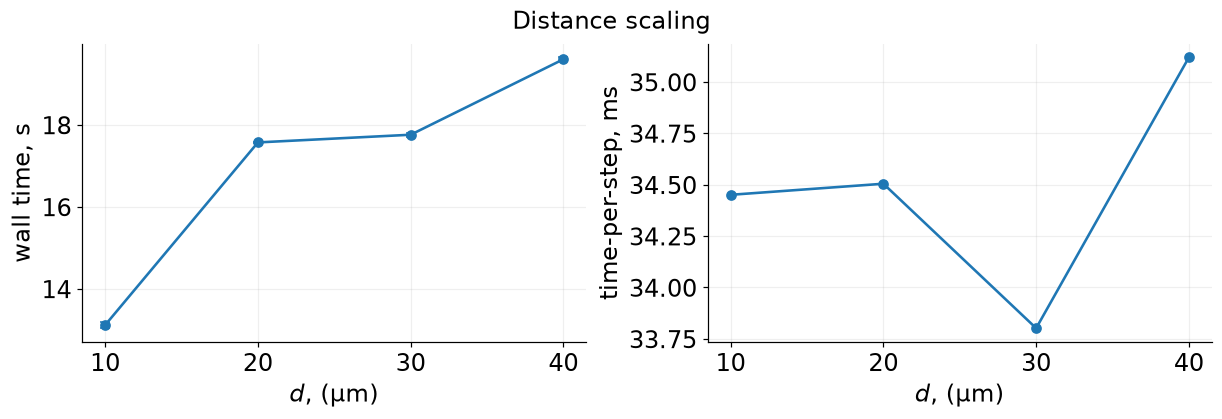

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


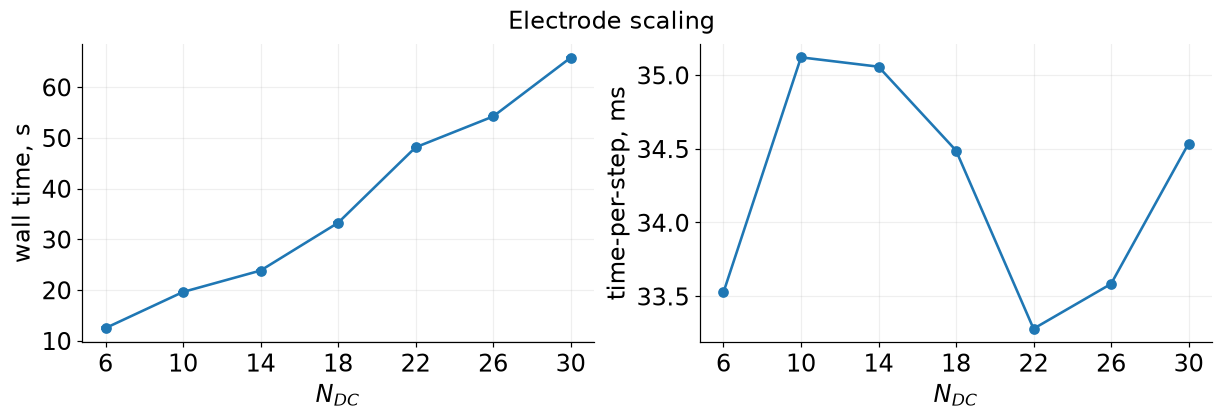

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


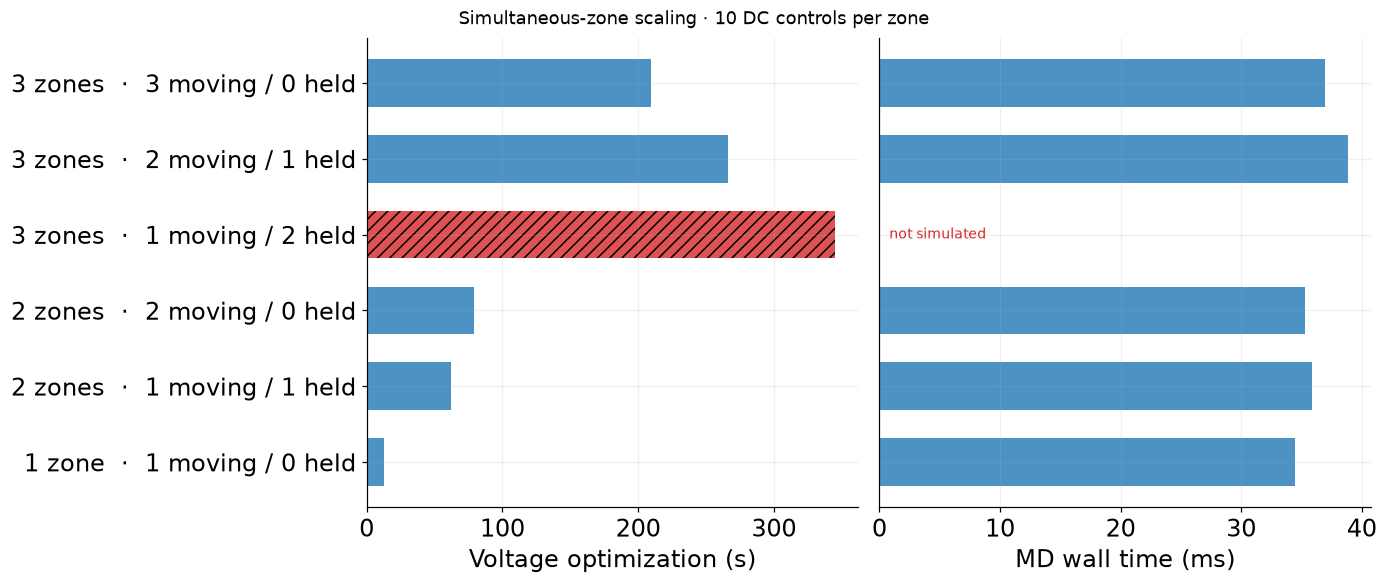

In [32]:
def pub_runtime_points(ax, frame, xcol, ycol, iqrcol, factor=1., label=None):
    x = pd.to_numeric(frame[xcol], errors='coerce').to_numpy(dtype=float)
    y = pd.to_numeric(frame[ycol], errors='coerce').to_numpy(dtype=float) * factor
    good = pub_bool(frame['all_checks_pass']).to_numpy() & np.isfinite(y)
    bad = (~pub_bool(frame['all_checks_pass']).to_numpy()) & np.isfinite(y)
    if iqrcol in frame:
        spread = pd.to_numeric(frame[iqrcol], errors='coerce').to_numpy(dtype=float) * factor / 2
    else:
        spread = np.full_like(y, np.nan)
    if np.any(good):
        ax.plot(x[good], y[good], 'o-', ms=6, lw=1.7,
                color='C0', label=label or 'Verified')
        valid_uncertainty = good & np.isfinite(spread) & (spread > 0)
        if np.any(valid_uncertainty):
            ax.errorbar(x[valid_uncertainty], y[valid_uncertainty],
                        yerr=spread[valid_uncertainty], fmt='none',
                        ecolor='C0', capsize=3, lw=1)
    if np.any(bad):
        ax.scatter(x[bad], y[bad], marker='x', s=85, linewidths=2,
                   color='C3', label='Not verified', zorder=5)

if not pub_main.empty:
    with plt.rc_context({'font.size': 16, 'axes.grid': True,
                         'grid.alpha': .2, 'axes.spines.top': False,
                         'axes.spines.right': False}):
        for family, title, xcol, xlab, stem in [
            ('d_scale', 'Distance scaling', 'distance_um',
             r'$d$, (µm)', 'pub_distance_runtime'),
            ('n_s_scale', 'Electrode scaling', 'n_variables',
             r'$N_{DC}$', 'pub_electrode_runtime'),
        ]:
            part = pub_main[pub_main['family'] == family].sort_values(xcol)
            fig, axs = plt.subplots(1, 2, figsize=(11, 3.7), layout='constrained')
            pub_runtime_points(axs[0], part, xcol, 'optimization_median_s',
                               'optimization_iqr_s')
            pub_runtime_points(axs[1], part, xcol, 'with_dump_step_time_s',
                               'with_dump_step_iqr_s', factor=1e3)
            axs[0].set(ylabel='wall time, s', xlabel=xlab)
            axs[1].set(ylabel='time-per-step, ms', xlabel=xlab)
            for ax in axs:
                ax.set_xticks(part[xcol].tolist())
            fig.suptitle(f'{title}', fontsize=16)
            handles, labels = axs[0].get_legend_handles_labels()
            if any('Not verified' in label for label in labels):
                axs[0].legend(frameon=False, fontsize=9)
            pub_save(fig, stem)
            plt.show()

        zones = pub_main[pub_main['family'] == 'n_z_scale'].copy()
        if not zones.empty:
            zones = zones.sort_values(['n_z', 'n_moving']).reset_index(drop=True)
            names = [f'{int(z)} zone{"s" if z>1 else ""}  ·  '
                     f'{int(m)} moving / {int(z-m)} held'
                     for z, m in zip(zones['n_z'], zones['n_moving'])]
            y = np.arange(len(zones))
            fig, axs = plt.subplots(1, 2, figsize=(12.5, 5.2),
                                    sharey=True, layout='constrained')
            verified = pub_bool(zones['all_checks_pass']).to_numpy()
            for j, (ax, column, scale, title) in enumerate([
                (axs[0], 'optimization_median_s', 1., 'Voltage optimization (s)'),
                (axs[1], 'with_dump_step_time_s', 1e3, 'MD wall time (ms)'),
            ]):
                vals = pd.to_numeric(zones[column], errors='coerce').to_numpy() * scale
                for k, (v, ok) in enumerate(zip(vals, verified)):
                    if np.isfinite(v):
                        ax.barh(k, v, color='C0' if ok else 'C3', alpha=.8,
                                hatch=None if ok else '///', height=.63)
                    elif j == 1:
                        ax.text(.02, k, 'not simulated', va='center', fontsize=9,
                                transform=ax.get_yaxis_transform(), color='C3')
                ax.set_xlabel(title)
                ax.invert_yaxis()
            axs[0].set(yticks=y, yticklabels=names)
            axs[1].tick_params(axis='y', left=False, labelleft=False)
            fig.suptitle('Simultaneous-zone scaling · 10 DC controls per zone', fontsize=12)
            pub_save(fig, 'pub_zone_runtime')
            plt.show()


### 13c. Static versus shuttling time-per-step

This compares the seven shuttling cases (6–30 optimized DC controls, one ion, 40 µm travel) against the measured one-ion static-DC baseline.


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


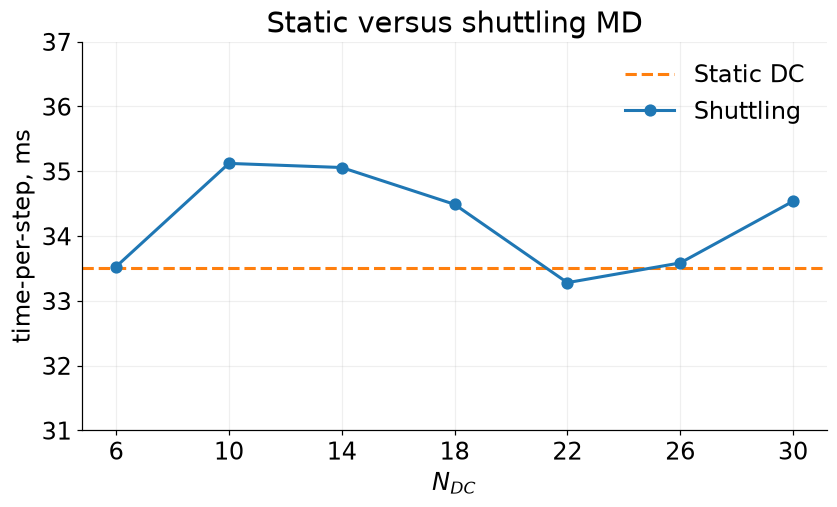

One-ion static reference: 33.502 ms/step, 1 matched timing pair(s).
The reference is constant across x because no separate static run was made for each optimized-electrode count.


In [34]:
if pub_main.empty or pub_baseline.empty:
    print('Missing summary or static-baseline measurements.')
else:
    ns = pub_main[pub_main['family'] == 'n_s_scale'].sort_values('n_variables')
    static_ref = pub_baseline[
        (pub_baseline['kind'] == 'static_dc') &
        (pub_baseline['mode'] == 'with_dump') &
        (pub_baseline['n_z'] == 1)
    ]
    if len(static_ref) != 1 or not np.isfinite(static_ref['step_time_s'].iloc[0]):
        print('A measured one-zone static-DC baseline is required for this plot.')
    else:
        ref_ms = float(static_ref['step_time_s'].iloc[0]) * 1e3
        x = ns['n_variables'].to_numpy(dtype=int)
        y = ns['with_dump_step_time_s'].to_numpy(dtype=float)*1e3
        ok = pub_bool(ns['all_checks_pass']).to_numpy() & np.isfinite(y)
        with plt.rc_context({'font.size': 16, 'axes.grid': True,
                             'grid.alpha': .2, 'axes.spines.top': False,
                             'axes.spines.right': False}):
            fig, ax = plt.subplots(figsize=(7.5, 4.5), layout='constrained')
            ax.axhline(ref_ms, color='C1', lw=2, linestyle='--',
                       label=f'Static DC')
            ax.plot(x[ok], y[ok], 'o-', color='C0', lw=2, ms=7,
                    label='Shuttling')
            iqr_ms = ns['with_dump_step_iqr_s'].to_numpy(dtype=float)*500
            unc = ok & np.isfinite(iqr_ms) & (iqr_ms > 0)
            if np.any(unc):
                ax.errorbar(x[unc], y[unc], yerr=iqr_ms[unc],
                            fmt='none', ecolor='C0', capsize=3)
            if np.any((~ok) & np.isfinite(y)):
                ax.plot(x[~ok], y[~ok], 'x', color='C3', ms=9, label='Not verified')
            ax.set(xlabel=r'$N_{DC}$',
                   ylabel='time-per-step, ms',
                   xticks=x, title='Static versus shuttling MD')
            ax.set_ylim(31,37)
            ax.legend(frameon=False, fontsize=16, loc='best')
            pub_save(fig, 'pub_static_vs_shuttling_electrode_scaling')
            plt.show()
        print(f'One-ion static reference: {ref_ms:.3f} ms/step, '
              f'{int(static_ref["n_timing_pairs"].iloc[0])} matched timing pair(s).')
        print('The reference is constant across x because no separate static run was made '
              'for each optimized-electrode count.')


### 13d. Verification

The fitted-minimum position error and MD secular RMSE are shown explicitly. A failed potential check remains visible even when MD was intentionally blocked. The threshold is taken from the benchmark configuration.


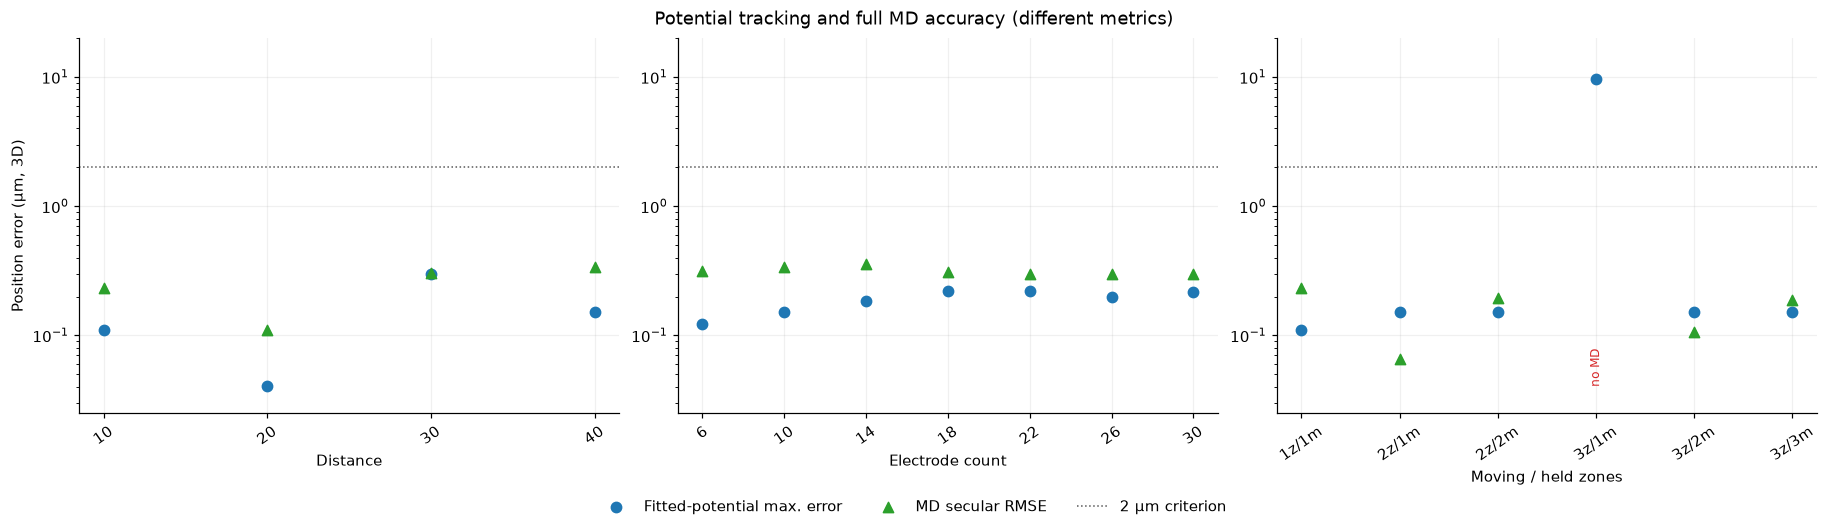

In [ ]:
if not pub_main.empty:
    threshold = float(MAX_MINIMUM_ERROR_UM)
    with plt.rc_context({'font.size': 10, 'axes.grid': True,
                         'grid.alpha': .19, 'axes.spines.top': False,
                         'axes.spines.right': False}):
        fig, axs = plt.subplots(1, 3, figsize=(16.5, 4.4), layout='constrained')
        for ax, family, title in zip(axs,
                ('d_scale', 'n_s_scale', 'n_z_scale'),
                ('Distance', 'Electrode count', 'Moving / held zones')):
            p = pub_main.loc[pub_main['family'] == family].copy()
            if family == 'd_scale':
                p = p.sort_values('distance_um')
                labels = [f'{v:g}' for v in p['distance_um']]
            elif family == 'n_s_scale':
                p = p.sort_values('n_variables')
                labels = [str(int(v)) for v in p['n_variables']]
            else:
                p = p.sort_values(['n_z','n_moving'])
                labels = [f'{int(z)}z/{int(m)}m' for z,m in zip(p['n_z'], p['n_moving'])]
            xx = np.arange(len(p))
            for offset, col, lab, marker, color in [
                (-.2, 'fitted_max_error_3d_um', 'Fitted-potential max. error', 'o', 'C0'),
                ( .2, 'trajectory_rmse_max_um', 'MD secular RMSE', '^', 'C2'),
            ]:
                values = pd.to_numeric(p[col], errors='coerce').to_numpy(dtype=float)
                mask = np.isfinite(values)
                ax.scatter(xx[mask]+0*offset, values[mask], marker=marker, color=color,
                           s=45, label=lab, zorder=4)
            ax.axhline(threshold, linestyle=':', color='0.35', lw=1,
                       label=f'{threshold:g} µm criterion')
            missing_md = pd.to_numeric(p['trajectory_rmse_max_um'],
                                       errors='coerce').isna().to_numpy()
            for i, missing in enumerate(missing_md):
                if missing:
                    ax.text(i, 0.04, 'no MD', rotation=90, va='bottom', ha='center',
                            fontsize=8, color='C3')
            ax.set(xticks=xx, xticklabels=labels, xlabel=title,
                   yscale='log', ylim=(.025, 20.))
            if ax is axs[0]:
                ax.set_ylabel('Position error (µm, 3D)')
            ax.tick_params(axis='x', labelrotation=35)
        handles, labels = axs[0].get_legend_handles_labels()
        fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(.5, -.08), ncol=3,
                   frameon=False)
        fig.suptitle('Potential tracking and full MD accuracy (different metrics)', fontsize=12)
        pub_save(fig, 'pub_verification_by_sweep')
        plt.show()


### 13e. Trajectories

Comparison between target and resulting ion trajectory from simulation.


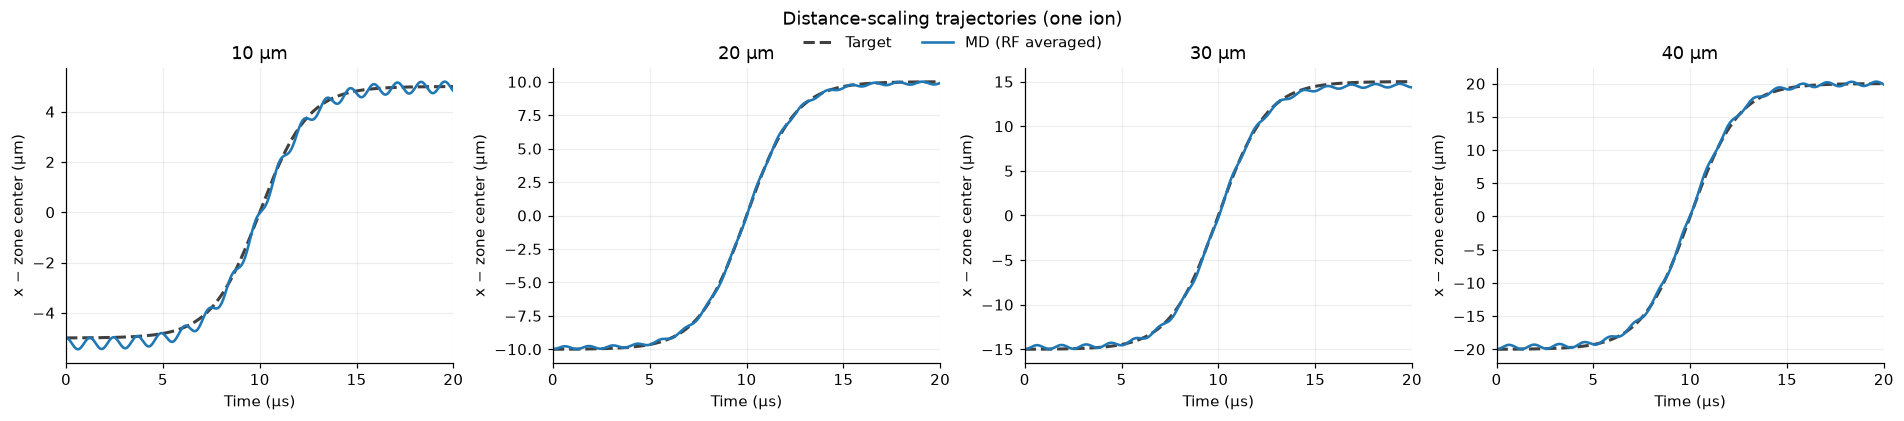

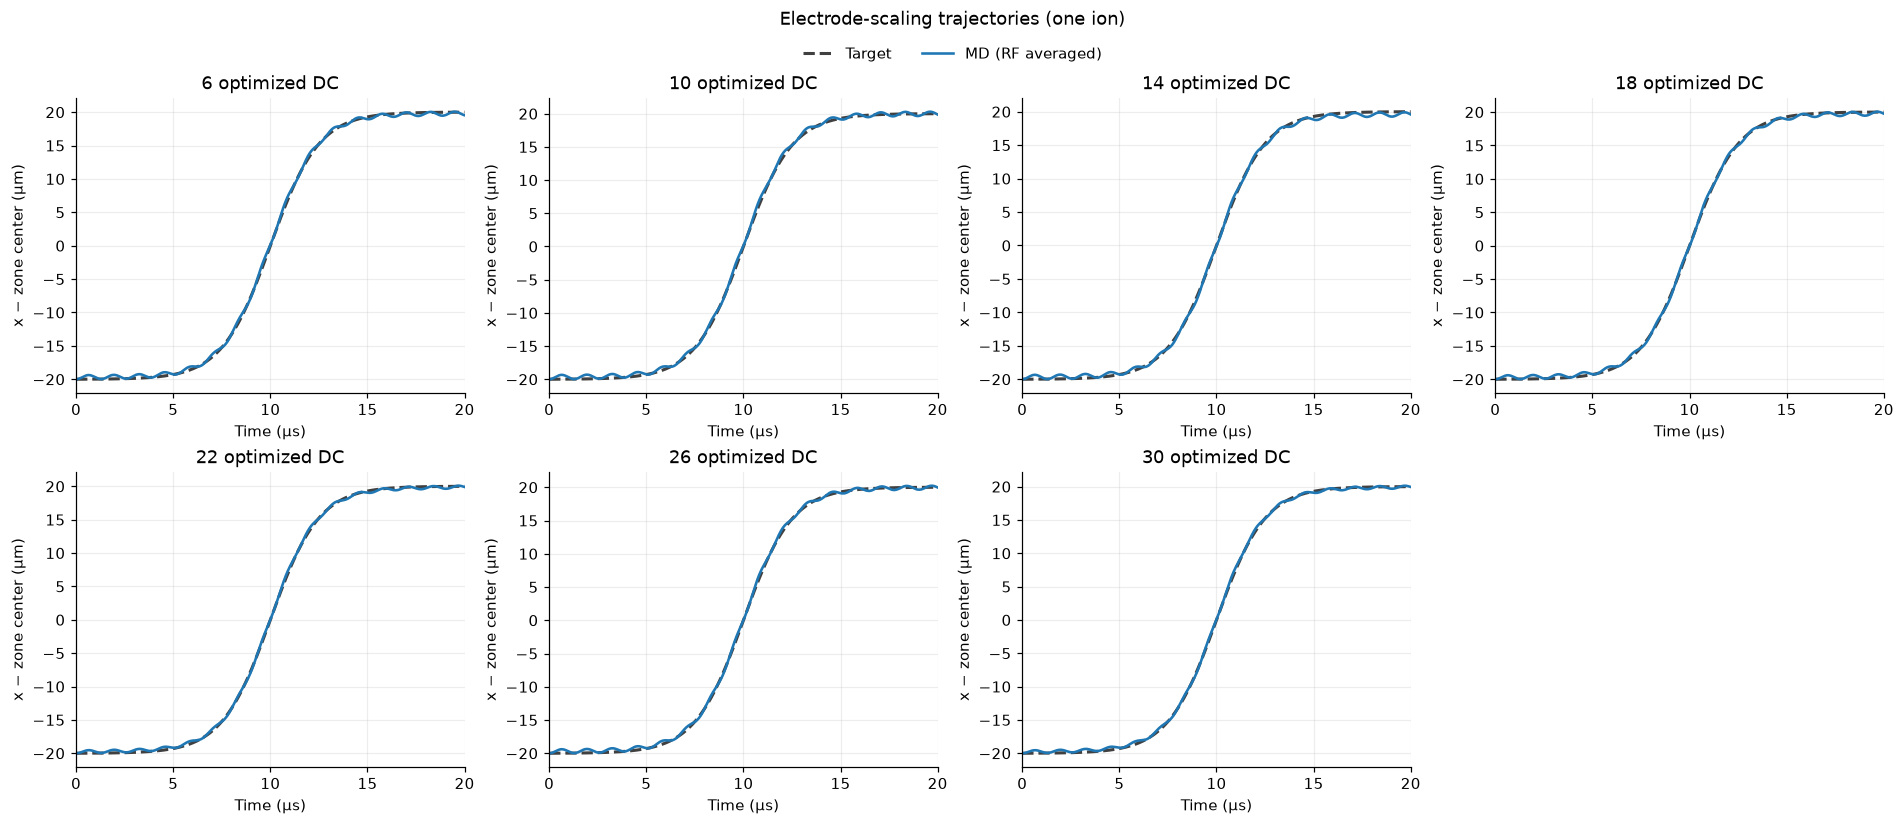

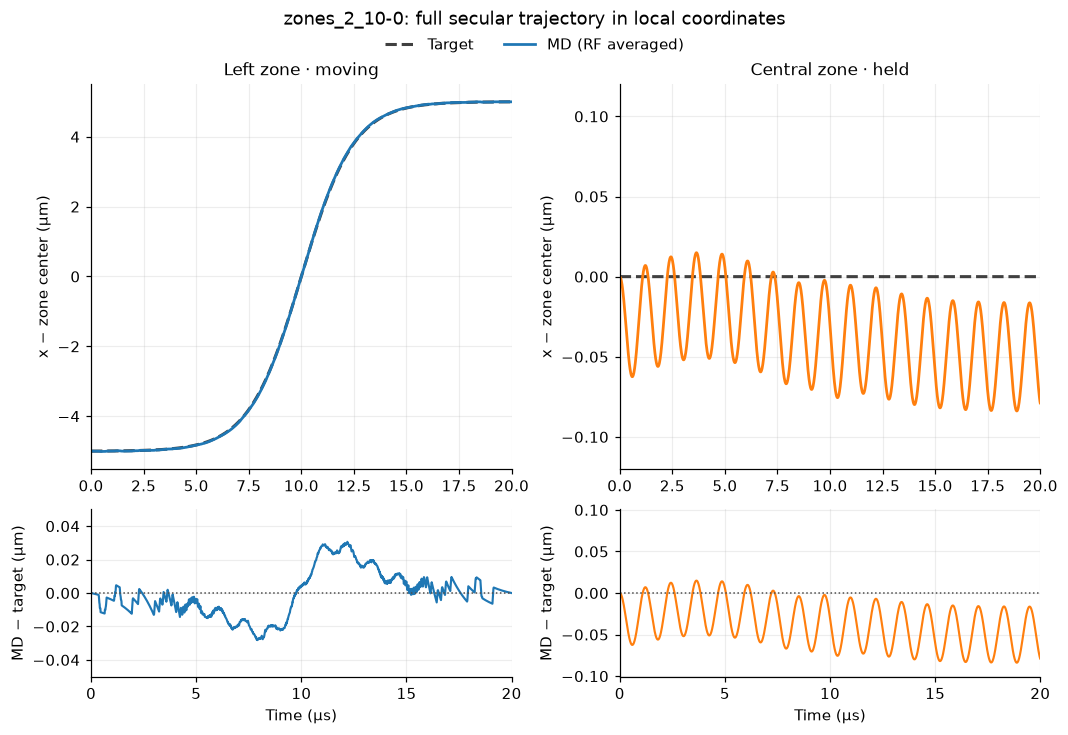

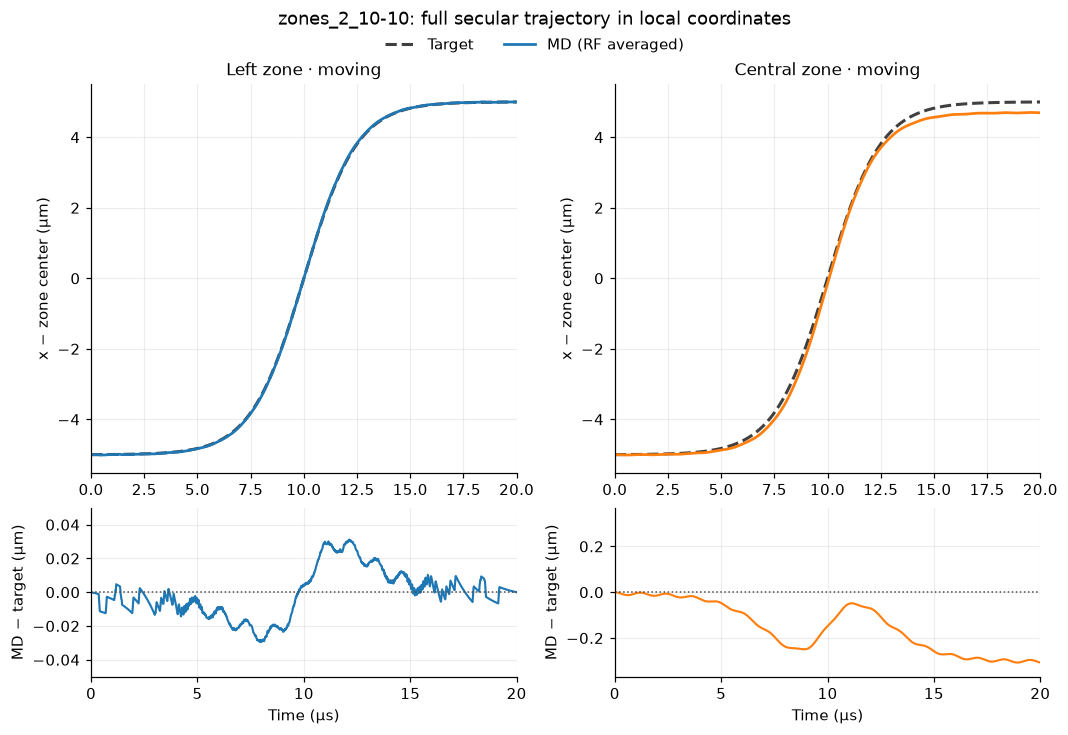

zones_3_0-10-0: full MD trajectory unavailable (not plotted).


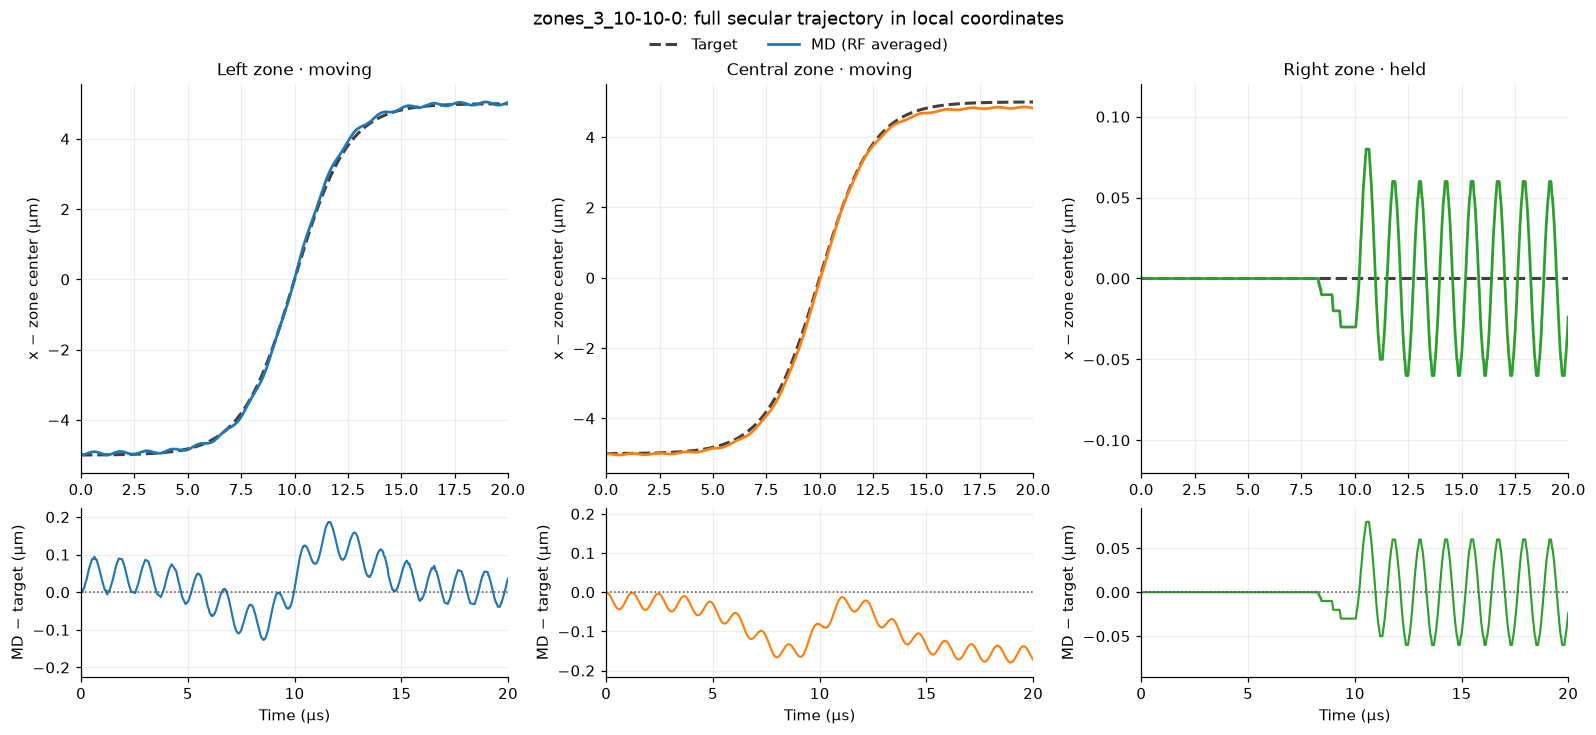

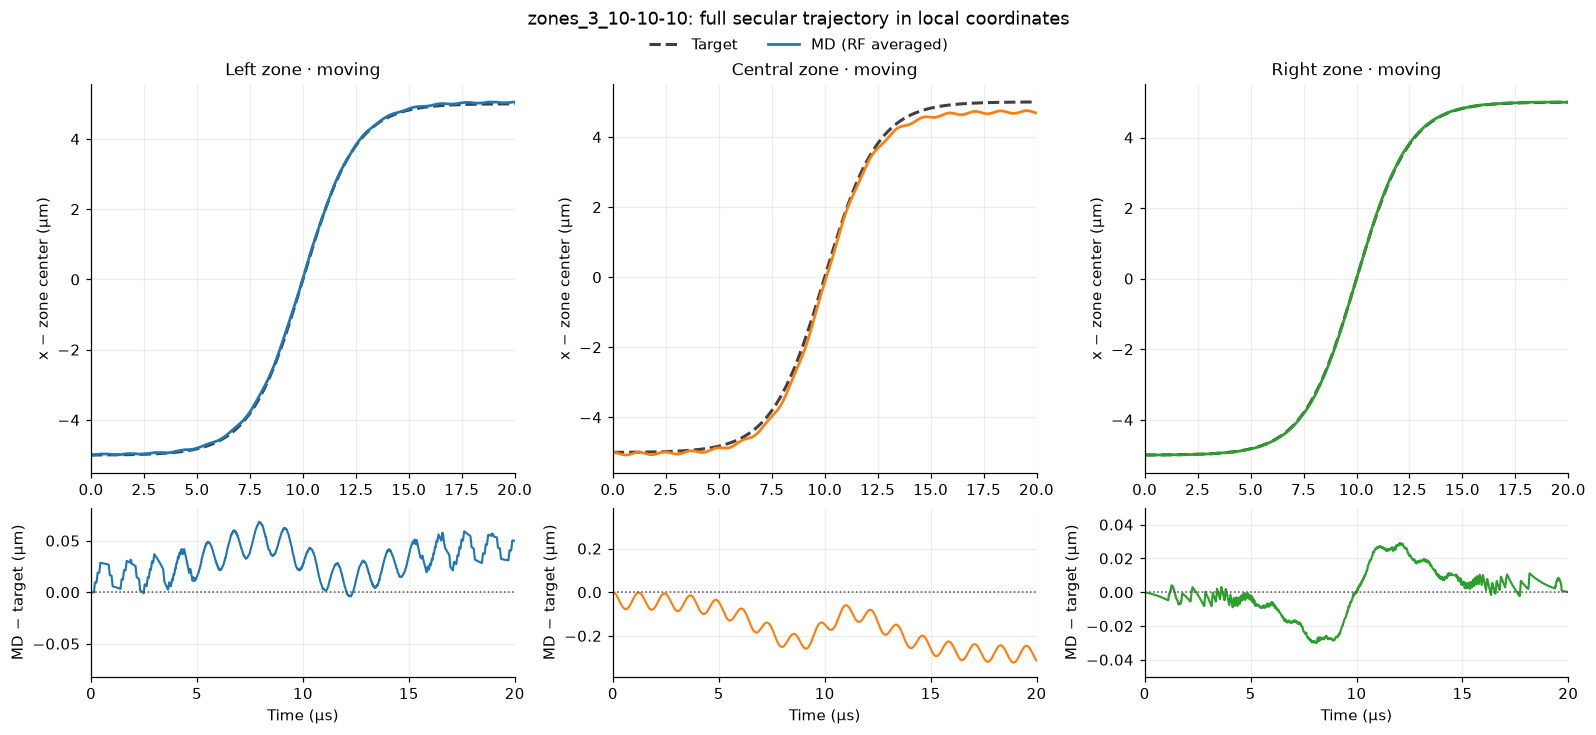

In [ ]:
def pub_case_trajectory(case_id):
    case = pub_case_by_id[case_id]
    source_id = case.get('source_case_id', case_id)
    if pub_traces.empty:
        return pd.DataFrame(), case
    part = pub_traces[pub_traces['case_id'] == source_id]
    return part, case

def pub_zone_trajectory(case_id, max_plot_points=1600):
    points, case = pub_case_trajectory(case_id)
    if points.empty:
        print(f'{case_id}: full MD trajectory unavailable (not plotted).')
        return
    n_z = case['n_z']
    fig, axes = plt.subplots(2, n_z, figsize=(4.8*n_z, 6.1),
                             squeeze=False, layout='constrained',
                             gridspec_kw={'height_ratios': [2.3, 1.]})
    for j, zone in enumerate(case['zone_names']):
        block = points[points['zone'] == zone].sort_values('t_us')
        if block.empty:
            axes[0, j].text(.5, .5, 'No trajectory', transform=axes[0,j].transAxes,
                            ha='center')
            continue
        stride = max(1, len(block)//max_plot_points)
        block = block.iloc[::stride]
        time_us = block['t_us'].to_numpy(dtype=float)
        center_um = float(case['centers_um'][j, 0])
        target = block['target_x_um'].to_numpy(dtype=float) - center_um
        md = block['secular_x_um'].to_numpy(dtype=float) - center_um
        err = md - target
        ax_top, ax_err = axes[:, j]
        ax_top.plot(time_us, target, '--', lw=2, color='0.25', label='Target')
        ax_top.plot(time_us, md, '-', lw=1.8, color=f'C{j}', label='MD (RF averaged)')
        role = 'held' if float(case['distances_um'][j]) == 0 else 'moving'
        ax_top.set_title(f'{zone.capitalize()} zone · {role}', fontsize=11)
        ax_top.set_ylabel('x − zone center (µm)')
        ax_top.set_xlim(0, 20)
        if role == 'held':
            ymax = max(.12, 1.25*np.nanmax(np.abs(np.r_[target, md])))
            ax_top.set_ylim(-ymax, ymax)
        ax_err.plot(time_us, err, color=f'C{j}', lw=1.4)
        ax_err.axhline(0., color='0.3', lw=1, linestyle=':')
        ax_err.set_ylabel('MD − target (µm)')
        ax_err.set_xlabel('Time (µs)')
        ax_err.set_xlim(0, 20)
        ax_err.set_xticks([0, 5, 10, 15, 20])
        emax = max(.05, np.nanmax(np.abs(err))*1.2)
        ax_err.set_ylim(-emax, emax)
        for ax in (ax_top, ax_err):
            ax.grid(alpha=.22)
            ax.spines[['top','right']].set_visible(False)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(.5, 1.05), ncol=2, frameon=False)
    fig.suptitle(f'{case_id}: full secular trajectory in local coordinates',
                 y=1.07, fontsize=12)
    pub_save(fig, f'pub_local_trajectory_{case_id}')
    plt.show()

def pub_single_zone_grid(family, max_plot_points=900):
    assert family in ('d_scale', 'n_s_scale')
    cases = [case for case in CASES if case['family'] == family]
    cases.sort(key=lambda q: (q['distances_um'][0] if family == 'd_scale'
                              else q['n_variables']))
    ncols = min(4, len(cases))
    nrows = int(np.ceil(len(cases)/ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.3*ncols, 3.4*nrows),
                             squeeze=False, layout='constrained')
    for ax, case in zip(axes.flat, cases):
        points, _ = pub_case_trajectory(case['case_id'])
        if points.empty:
            ax.text(.5, .5, 'Full MD not available', transform=ax.transAxes,
                    ha='center', va='center')
            continue
        p = points[points['zone'] == case['zone_names'][0]].sort_values('t_us')
        p = p.iloc[::max(1,len(p)//max_plot_points)]
        t = p['t_us'].to_numpy(dtype=float)
        origin = float(case['centers_um'][0, 0])
        ax.plot(t, p['target_x_um'].to_numpy()-origin,
                '--', color='0.25', lw=2, label='Target')
        ax.plot(t, p['secular_x_um'].to_numpy()-origin,
                '-', color='C0', lw=1.7, label='MD (RF averaged)')
        desc = (f'{case["distances_um"][0]:g} µm' if family == 'd_scale'
                else f'{case["n_variables"]} optimized DC')
        ax.set_title(desc)
        ax.set(xlabel='Time (µs)', ylabel='x − zone center (µm)', xlim=(0,20))
        ax.set_xticks([0,5,10,15,20])
        ax.grid(alpha=.22)
        ax.spines[['top','right']].set_visible(False)
    for ax in axes.flat[len(cases):]:
        ax.set_visible(False)
    hs, ls = axes.flat[0].get_legend_handles_labels()
    if hs:
        fig.legend(hs, ls, loc='upper center', bbox_to_anchor=(.5, 1.05), ncol=2, frameon=False)
    fig.suptitle(('Distance-scaling' if family == 'd_scale' else 'Electrode-scaling')
                 + ' trajectories (one ion)', y=1.08, fontsize=12)
    pub_save(fig, f'pub_trajectory_grid_{family}')
    plt.show()

if not pub_traces.empty:
    with plt.rc_context({'font.size': 10, 'savefig.facecolor': 'white'}):
        pub_single_zone_grid('d_scale')
        pub_single_zone_grid('n_s_scale')
        for case in CASES:
            if case['family'] == 'n_z_scale' and case['n_z'] > 1:
                pub_zone_trajectory(case['case_id'])
else:
    print('Full MD trajectory CSV not found; local-axis figures were not generated.')
